# 🐍 Python Master Recap for ML/DL Researchers

**A 2 to 3 hour hands-on refresher of every core Python concept, explained in plain words.**

This notebook follows the chapter order of Asabeneh's
[30 Days of Python](https://github.com/Asabeneh/30-Days-Of-Python), but trimmed and reshaped for people
who train models. Every example uses things you meet in research: losses, configs, datasets, metrics, experiment logs.

### How to use it
1. Run cells from top to bottom with **Shift + Enter**.
2. Each chapter goes: **idea → example code → 🧠 Practice → empty cell for you**.
3. Solutions hide under **💡 Show solution**. Try first, peek later.
4. Feel free to break things. Errors are part of learning.

> ⚠️ Some chapters write small files into a folder called `recap_files/`. You can delete it at the end.

## 🗺️ Roadmap and time plan

| Part | Chapters | Time |
|---|---|---|
| **A. Foundations** | 1 Basics · 2 Variables · 3 Operators · 4 Strings · 5 Lists · 6 Tuples · 7 Sets · 8 Dictionaries | ~45 min |
| **B. Logic and functions** | 9 Conditionals · 10 Loops · 11 Functions · 12 Modules · 13 Comprehensions · 14 Higher-order functions | ~40 min |
| **C. Writing robust code** | 15 Errors · 16 Date and time · 17 Exception handling · 18 Regex · 19 Files · 20 Packages and venvs | ~30 min |
| **D. OOP and the data stack** | 21 Classes · 22 NumPy and statistics · 23 Pandas · 24 Web data and APIs | ~40 min |
| **E. Research toolkit** | 25 Power tools (generators, logging, plots) · 26 Capstone: logistic regression from scratch | ~25 min |

Quick setup check 👇 (if this fails, run `pip install numpy pandas matplotlib`).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("Pandas    :", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

Python    : 3.11.9
NumPy     : 2.3.5
Pandas    : 2.2.3
Matplotlib: 3.9.2


---
# Part A · Foundations

## Chapter 1 · Python Basics ⏱️ ~4 min

Python reads your code **line by line, top to bottom**. A few rules:

- `#` starts a **comment**. Python ignores it. Use it to explain *why*, not *what*.
- **Indentation** (4 spaces) creates code blocks. Other languages use `{ }`. Python uses spaces, so wrong spacing means a bug.
- `print()` shows things. `type()` tells you what kind of thing it is.

| Type | Example | ML use |
|---|---|---|
| `int` | `32` | batch size, epochs |
| `float` | `0.001` | learning rate, loss |
| `str` | `"resnet18"` | model name, file path |
| `bool` | `True` | `use_gpu = True` |
| `NoneType` | `None` | "no value yet" |
| `list` | `[0.9, 0.7]` | loss history |
| `tuple` | `(224, 224, 3)` | image shape |
| `set` | `{"cat", "dog"}` | unique labels |
| `dict` | `{"lr": 1e-3}` | config |

In [2]:
# This is a comment. Python skips it.
print("Hello, ML world!")
print(3 + 4, 3 - 4, 3 * 4, 3 / 4)

print(type(10), type(3.14), type(1 + 2j), type("text"), type(True), type(None))
print(type([1, 2]), type((1, 2)), type({1, 2}), type({"lr": 0.001}))

Hello, ML world!
7 -1 12 0.75
<class 'int'> <class 'float'> <class 'complex'> <class 'str'> <class 'bool'> <class 'NoneType'>
<class 'list'> <class 'tuple'> <class 'set'> <class 'dict'>


> 🔬 **ML tip:** Many bugs in ML code are *type* or *shape* bugs. `type()` (and later `.shape`) are your best debugging friends.

### 🧠 Practice

1. Print your name and your research topic in a single `print()`.
2. Check the type of `1e-3`, `None` and `"0.5"`. Which one surprises you?
3. Find the Euclidean distance between points (2, 3) and (10, 8). *(Hint: `** 0.5` is a square root.)*

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
print("Name: Ada", "| Topic: medical imaging")
print(type(1e-3), type(None), type("0.5"))   # "0.5" is a str, not a float!
print(((10 - 2) ** 2 + (8 - 3) ** 2) ** 0.5)  # 9.433...
```

</details>

## Chapter 2 · Variables and Built-in Functions ⏱️ ~5 min

A **variable** is a name that points to a value. Write names in `snake_case`, make them meaningful,
and never start with a number.

**Casting** means changing a type: `int()`, `float()`, `str()`, `bool()`, `list()`.

**Built-in functions** come free with Python: `print, type, len, min, max, sum, round, abs, pow, sorted, help, dir`.

In [3]:
learning_rate = 0.001
batch_size, epochs = 32, 10          # assign many at once
model_name = "resnet18"
print(learning_rate, batch_size, epochs, model_name)

# Casting (changing type)
print(int("64"), float("0.5"), str(42), int(3.9))   # int() cuts decimals, it does NOT round
print(bool(0), bool(1), bool(""), bool("hi"))

# Handy built-ins
losses = [0.92, 0.71, 0.55, 0.48]
print(len(losses), min(losses), max(losses), sum(losses))
print("mean loss:", round(sum(losses) / len(losses), 3))
print(abs(-2.5), pow(2, 10), round(3.14159, 2))

big_number = 1_000_000       # underscores make big numbers readable
print(big_number)
# help(len)                  # uncomment to read the docs of any function

0.001 32 10 resnet18
64 0.5 42 3
False True False True
4 0.48 0.92 2.6599999999999997
mean loss: 0.665
2.5 1024 3.14
1000000


### 🧠 Practice

1. Create variables for a small config: `dataset_name`, `num_classes`, `dropout`.
2. A dataset has 50,000 images and the batch size is 32. How many batches per epoch if you **count the last partial batch too**?
3. Convert the string `"0.25"` to a number and double it.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
dataset_name, num_classes, dropout = "CIFAR-10", 10, 0.3
full_batches = 50000 // 32       # 1562
all_batches = -(-50000 // 32)    # ceiling division trick -> 1563
print(full_batches, all_batches)
print(float("0.25") * 2)
```

</details>

## Chapter 3 · Operators ⏱️ ~5 min

| Kind | Operators | Example |
|---|---|---|
| Arithmetic | `+ - * / // % **` | `7 // 2 = 3`, `7 % 2 = 1`, `2 ** 3 = 8` |
| Assignment | `= += -= *= /=` | `step += 1` |
| Comparison | `== != > < >= <=` | `acc > 0.9` gives `True/False` |
| Logical | `and or not` | `acc > 0.8 and loss < 0.5` |
| Membership | `in, not in` | `"cat" in labels` |
| Identity | `is, is not` | `x is None` |

`//` is floor division (drops the remainder). `%` gives the remainder. Very handy for "every N steps".

In [4]:
a, b = 7, 2
print(a + b, a - b, a * b, a / b, a // b, a % b, a ** b)

step = 0
step += 1
step *= 10
print("step:", step)

acc = 0.87
print(acc > 0.9, acc >= 0.85, acc == 0.87, acc != 0.5)
print(acc > 0.8 and acc < 0.9, 0.8 < acc < 0.9, not acc > 0.9)   # chained comparison works!
print("cat" in ["cat", "dog"], None is None)

# Floats are approximate!
print(0.1 + 0.2, 0.1 + 0.2 == 0.3)
import math
print(math.isclose(0.1 + 0.2, 0.3))

# "Log every 100 steps" pattern
for s in [0, 50, 100, 150, 200]:
    if s % 100 == 0:
        print("log at step", s)

9 5 14 3.5 3 1 49
step: 10
False True True True
True True True
True True
0.30000000000000004 False
True
log at step 0
log at step 100
log at step 200


> 🔬 **ML tip:** Never compare float metrics with `==`. Use `math.isclose()` or `np.isclose()`.

### 🧠 Practice

1. Is 2024 divisible by 8? Answer with one expression.
2. Compute the area of a circle with radius 5 using `**`.
3. You save a checkpoint every 5 epochs and train for 40. At `epoch = 37`, should you save? Is it the last epoch?

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
print(2024 % 8 == 0)                 # True
r = 5
print(3.14159 * r ** 2)
epoch, total = 37, 40
print(epoch % 5 == 0, epoch == total)  # False False
```

</details>

## Chapter 4 · Strings ⏱️ ~6 min

A **string** is text inside quotes: `'a'`, `"a"`, or `"""multi-line"""`. Strings are **immutable** (you can't change one character; you build a new string).

- **Indexing**: `s[0]` first, `s[-1]` last. **Slicing**: `s[start:stop:step]` (stop is not included).
- **Methods**: `.lower() .upper() .strip() .split() .replace() .startswith() .count() .find()`
- **f-strings** are the modern way to format: `f"loss={loss:.4f}"`

| Format | Meaning | Output |
|---|---|---|
| `{x:.4f}` | 4 decimals | `0.1235` |
| `{x:.2%}` | percent | `91.23%` |
| `{n:,}` | thousand separators | `110,000,000` |
| `{n:03d}` | pad with zeros | `007` |
| `{s:<10}` / `{s:>10}` | left / right align | table columns |

In [5]:
s = "transformer"
print(s[0], s[-1], s[0:5], s[::-1], len(s))
print(s.upper(), s.capitalize(), s.replace("former", "ers"), s.startswith("trans"), s.count("r"))

text = "  Deep Learning is Fun  "
print(repr(text.strip()), text.lower(), text.split())

# f-strings: the training-log favourite
epoch, loss, acc = 3, 0.123456, 0.9123
print(f"Epoch {epoch:02d} | loss={loss:.4f} | acc={acc:.2%}")
print(f"{'model':<10}|{'params':>13}")
print(f"{'bert-base':<10}|{110_000_000:>13,}")
print(f"{loss=}")            # handy debug print: shows name and value

words = ["the", "model", "learns"]
sentence = " ".join(words)   # list -> string
print(sentence, sentence.split())   # string -> list

print("line1\nline2\tTabbed")      # escape characters
print(r"C:\new\data")              # raw string: backslashes stay as-is (great for regex & Windows paths)

t r trans remrofsnart 11
TRANSFORMER Transformer transers True 3
'Deep Learning is Fun'   deep learning is fun   ['Deep', 'Learning', 'is', 'Fun']
Epoch 03 | loss=0.1235 | acc=91.23%
model     |       params
bert-base |  110,000,000
loss=0.123456
the model learns ['the', 'model', 'learns']
line1
line2	Tabbed
C:\new\data


### 🧠 Practice

1. From the filename `"resnet50_epoch12_acc0.913.pt"`, pull out the epoch (as `int`) and accuracy (as `float`) using `split`.
2. Print a small aligned table (header + 2 rows) of model name, params (millions) and accuracy using f-strings.
3. Clean `"  Attention Is All You Need  "`: strip, lowercase, split into words, and count them.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
fname = "resnet50_epoch12_acc0.913.pt"
parts = fname.removesuffix(".pt").split("_")     # ['resnet50', 'epoch12', 'acc0.913']
epoch = int(parts[1].replace("epoch", ""))
acc = float(parts[2].replace("acc", ""))
print(epoch, acc)

print(f"{'model':<12}{'params(M)':>10}{'acc':>8}")
print(f"{'resnet18':<12}{11.7:>10.1f}{0.912:>8.1%}")
print(f"{'vit-b16':<12}{86.6:>10.1f}{0.934:>8.1%}")

words = "  Attention Is All You Need  ".strip().lower().split()
print(words, len(words))
```

</details>

## Chapter 5 · Lists ⏱️ ~6 min

A **list** is an ordered, changeable collection: `[1, "a", 2.5]`. Perfect for collecting metrics epoch by epoch.

| Action | Code |
|---|---|
| add one / many | `.append(x)` / `.extend([..])` |
| insert at position | `.insert(i, x)` |
| remove by value / by index | `.remove(x)` / `.pop(i)` |
| sort in place / new sorted copy | `.sort()` / `sorted(lst)` |
| find position / count | `.index(x)` / `.count(x)` |
| copy | `.copy()` or `lst[:]` |

In [6]:
losses = [0.9, 0.7, 0.6]
losses.append(0.55)
losses.extend([0.5, 0.48])
losses.insert(0, 1.2)
print(losses, len(losses))
print(losses[0], losses[-1], losses[1:4], losses[::2])

last = losses.pop()          # removes & returns the last item
losses.remove(1.2)           # removes the first 1.2
print("popped:", last, "->", losses)

scores = [0.7, 0.9, 0.8]
print(sorted(scores), sorted(scores, reverse=True), scores)  # sorted() returns a NEW list
scores.sort()                                                # .sort() changes the list itself
print(scores)

first, *middle, final = [1, 2, 3, 4, 5]    # star-unpacking
print(first, middle, final)

matrix = [[1, 2, 3], [4, 5, 6]]            # list of lists = a tiny "matrix"
print(matrix[1][2], len(matrix), len(matrix[0]))

[1.2, 0.9, 0.7, 0.6, 0.55, 0.5, 0.48] 7
1.2 0.48 [0.9, 0.7, 0.6] [1.2, 0.7, 0.55, 0.48]
popped: 0.48 -> [0.9, 0.7, 0.6, 0.55, 0.5]
[0.7, 0.8, 0.9] [0.9, 0.8, 0.7] [0.7, 0.9, 0.8]
[0.7, 0.8, 0.9]
1 [2, 3, 4] 5
6 2 3


⚠️ **The copy trap.** `b = a` does **not** copy a list. It just gives the same list a second name.

In [7]:
a = [1, 2, 3]
b = a          # same list, two names!
c = a.copy()   # a real copy
a.append(99)
print("a:", a, "| b:", b, "| c:", c)

a: [1, 2, 3, 99] | b: [1, 2, 3, 99] | c: [1, 2, 3]


> 🔬 **ML tip:** Lists are great for collecting things but slow for math. For numbers, use NumPy arrays (Chapter 22).

### 🧠 Practice

1. Store 5 validation accuracies in a list. Find the best one and its **epoch number** (epochs start at 1).
2. Make a list of 10 sample IDs and split it into train (first 8) and test (last 2) with slicing.
3. Make a list of learning rates `[1e-3, 1e-2, 1e-4]`, add `3e-4`, then sort from largest to smallest.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
val_acc = [0.71, 0.78, 0.83, 0.81, 0.80]
best = max(val_acc)
print(best, "at epoch", val_acc.index(best) + 1)

ids = list(range(100, 110))
train, test = ids[:8], ids[8:]
print(train, test)

lrs = [1e-3, 1e-2, 1e-4]
lrs.append(3e-4)
lrs.sort(reverse=True)
print(lrs)
```

</details>

## Chapter 6 · Tuples ⏱️ ~4 min

A **tuple** is like a list but **cannot change** after creation: `(224, 224, 3)`.
Use tuples for fixed things: shapes, coordinates, and returning several values from a function.

- **Unpacking**: `h, w, c = (224, 224, 3)`
- One-item tuple needs a comma: `(5,)`. Without it, `(5)` is just the number 5.
- Tuples can be dictionary keys. Lists cannot.

In [8]:
image_shape = (224, 224, 3)
h, w, c = image_shape
print(h, w, c, image_shape[0], len(image_shape))
# image_shape[0] = 128   # <- TypeError: tuples can't be changed

single = (5,)
print(type(single), type((5)))

full_batches, leftover = divmod(50_000, 32)   # divmod returns a tuple
print(full_batches, leftover)

a, b = 1, 2
a, b = b, a        # swap in one line (packing + unpacking)
print(a, b)

print((1, 2) + (3,), (0,) * 3, image_shape.count(224), image_shape.index(3))
results = {("resnet", 0.001): 0.91, ("resnet", 0.01): 0.88}   # tuple as a dict key
print(results[("resnet", 0.001)])

224 224 3 224 3
<class 'tuple'> <class 'int'>
1562 16
2 1
(1, 2, 3) (0, 0, 0) 2 2
0.91


### 🧠 Practice

1. A batch has shape `(32, 3, 224, 224)`. Unpack it and compute the number of values in **one** image.
2. Convert the list `[1, 2, 3]` to a tuple and back to a list.
3. With 1000 samples and batch size 64, use `divmod` to get full batches and leftover samples.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
b, c, h, w = (32, 3, 224, 224)
print(c * h * w)              # 150528
t = tuple([1, 2, 3]); l = list(t)
print(t, l)
print(divmod(1000, 64))       # (15, 40)
```

</details>

## Chapter 7 · Sets ⏱️ ~4 min

A **set** keeps only **unique** items, has **no order**, and checks membership very fast.

| Operation | Symbol | Meaning |
|---|---|---|
| union | `a \| b` | everything |
| intersection | `a & b` | in both |
| difference | `a - b` | in a, not in b |
| symmetric diff | `a ^ b` | in one, not both |

> 🔬 **ML tip:** Sets are the fastest way to catch **data leakage**: patient or image IDs that appear in both train and test.

In [9]:
labels = ["cat", "dog", "cat", "bird", "dog"]
classes = set(labels)
print(classes, len(classes))

train_ids = {1, 2, 3, 4, 5, 6}
test_ids = {5, 6, 7, 8}
print("Leaked IDs :", train_ids & test_ids)
print("All IDs    :", train_ids | test_ids)
print("Only train :", train_ids - test_ids)
print("Not shared :", train_ids ^ test_ids)
print({1, 2}.issubset(train_ids), 7 in test_ids)

classes.add("fish")
classes.discard("bird")      # no error if missing (remove() would raise one)
print(sorted(classes))

empty = set()                # careful: {} is an empty DICT, not a set
print(type(empty), type({}))

{'dog', 'cat', 'bird'} 3
Leaked IDs : {5, 6}
All IDs    : {1, 2, 3, 4, 5, 6, 7, 8}
Only train : {1, 2, 3, 4}
Not shared : {1, 2, 3, 4, 7, 8}
True True
['cat', 'dog', 'fish']
<class 'set'> <class 'dict'>


### 🧠 Practice

1. Count the unique words in `"the cat and the dog and the bird"`.
2. Train patients `{"P1","P2","P3","P4"}`, val patients `{"P3","P5","P6"}`. Find the leaked IDs and remove them from val.
3. Find words in vocab A that are missing from vocab B.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
print(len(set("the cat and the dog and the bird".split())))   # 5

train = {"P1", "P2", "P3", "P4"}
val = {"P3", "P5", "P6"}
leak = train & val
val = val - leak
print(leak, val)

vocab_a = {"hello", "world", "deep", "learning"}
vocab_b = {"hello", "machine", "learning"}
print(vocab_a - vocab_b)
```

</details>

## Chapter 8 · Dictionaries ⏱️ ~6 min

A **dict** maps **keys → values**: `{"lr": 0.001, "epochs": 10}`. It's how we store configs, metrics, and label maps.

| Action | Code |
|---|---|
| read (error if missing) | `d["lr"]` |
| read safely with default | `d.get("dropout", 0.0)` |
| add / change | `d["k"] = v`, `d.update({...})` |
| delete | `del d["k"]`, `d.pop("k")` |
| loop | `.keys()`, `.values()`, `.items()` |
| merge (Python 3.9+) | `base \| override` |

In [10]:
config = {"model": "resnet18", "lr": 1e-3, "batch_size": 32, "epochs": 10}
print(config["lr"], config.get("dropout", 0.0))

config["dropout"] = 0.2
config.update({"lr": 3e-4, "optimizer": "adam"})
del config["epochs"]
print(config)
print(list(config.keys()), "lr" in config)

for key, value in config.items():
    print(f"{key:>12}: {value}")

0.001 0.0
{'model': 'resnet18', 'lr': 0.0003, 'batch_size': 32, 'dropout': 0.2, 'optimizer': 'adam'}
['model', 'lr', 'batch_size', 'dropout', 'optimizer'] True
       model: resnet18
          lr: 0.0003
  batch_size: 32
     dropout: 0.2
   optimizer: adam


In [11]:
history = {"train_loss": [0.9, 0.6], "val_loss": [1.0, 0.7]}   # values can be lists
history["train_loss"].append(0.5)
print(history)

base = {"lr": 1e-3, "seed": 42}
override = {"lr": 5e-4}
print(base | override)          # merge: right side wins

label_counts = {}               # counting pattern
for y in ["cat", "dog", "cat", "cat"]:
    label_counts[y] = label_counts.get(y, 0) + 1
print(label_counts)

from collections import Counter, defaultdict   # ready-made helpers
print(Counter(["cat", "dog", "cat", "cat"]).most_common(1))
groups = defaultdict(list)
groups["cat"].append("img1.png")   # no KeyError, list is created automatically
print(dict(groups))

idx_to_class = {0: "cat", 1: "dog"}
class_to_idx = {v: k for k, v in idx_to_class.items()}   # reverse a mapping (see Ch 13)
print(class_to_idx)

{'train_loss': [0.9, 0.6, 0.5], 'val_loss': [1.0, 0.7]}
{'lr': 0.0005, 'seed': 42}
{'cat': 3, 'dog': 1}
[('cat', 3)]
{'cat': ['img1.png']}
{'cat': 0, 'dog': 1}


### 🧠 Practice

1. Build an experiment dict with `name`, a nested `metrics` dict (`acc`, `f1`), and a `tags` list. Print the F1 score.
2. Count each character in `"mississippi"` using a dict.
3. Given `scores = {"svm": 0.84, "rf": 0.88, "xgb": 0.90}`, find the best model name in one line.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
exp = {"name": "baseline", "metrics": {"acc": 0.91, "f1": 0.88}, "tags": ["cnn", "v1"]}
print(exp["metrics"]["f1"])

counts = {}
for ch in "mississippi":
    counts[ch] = counts.get(ch, 0) + 1
print(counts)

scores = {"svm": 0.84, "rf": 0.88, "xgb": 0.90}
print(max(scores, key=scores.get))   # 'xgb'
```

</details>

---
# Part B · Logic and Functions

## Chapter 9 · Conditionals ⏱️ ~5 min

`if / elif / else` lets code make decisions. Python checks conditions top to bottom and runs the **first** true block.

**Truthiness:** empty things (`0, 0.0, "", [], {}, None`) count as `False`. Everything else counts as `True`.

**One-line if (ternary):** `value = A if condition else B`

**`match` (Python 3.10+):** a clean way to branch on a value.

In [12]:
val_acc = 0.83
if val_acc >= 0.9:
    verdict = "excellent"
elif val_acc >= 0.8:
    verdict = "good"
else:
    verdict = "needs work"
print(verdict)

best_acc = 0.80
if val_acc > best_acc:
    best_acc = val_acc
    print("New best! Saving checkpoint...")

gpu_available = False
device = "cuda" if gpu_available else "cpu"
print(device)

for thing in [0, 1, "", "hi", [], [0], None]:
    print(f"{thing!r:>6} -> {bool(thing)}")

optimizer = "adam"
match optimizer:
    case "sgd":
        print("Using SGD")
    case "adam" | "adamw":
        print("Using the Adam family")
    case _:
        print("Unknown optimizer")

good
New best! Saving checkpoint...
cpu
     0 -> False
     1 -> True
    '' -> False
  'hi' -> True
    [] -> False
   [0] -> True
  None -> False
Using the Adam family


### 🧠 Practice

1. **Early stopping check.** `best_val_loss = 0.50`, `wait = 1`, `patience = 3`, `current = 0.52`. If current improves, update best and reset wait. Otherwise increase wait and print "Early stop!" when `wait >= patience`.
2. Turn a probability `p` into a label: `"positive"` if p > 0.55, `"negative"` if p < 0.45, else `"uncertain"`.
3. Give a letter grade: A (≥80), B (≥70), C (≥60), F otherwise.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
best_val_loss, wait, patience = 0.50, 1, 3
current = 0.52
if current < best_val_loss:
    best_val_loss, wait = current, 0
else:
    wait += 1
    if wait >= patience:
        print("Early stop!")
print(best_val_loss, wait)

p = 0.53
label = "positive" if p > 0.55 else "negative" if p < 0.45 else "uncertain"
print(label)

score = 78
if score >= 80: grade = "A"
elif score >= 70: grade = "B"
elif score >= 60: grade = "C"
else: grade = "F"
print(grade)
```

</details>

## Chapter 10 · Loops ⏱️ ~8 min

- `for x in something:` goes through each item.
- `range(start, stop, step)` makes number sequences (stop not included).
- `enumerate()` gives **index + item**. `zip()` walks **two lists together**.
- `while condition:` repeats until the condition becomes false.
- `break` exits the loop. `continue` skips to the next round.

In [13]:
for i in range(3):
    print("i =", i)
print(list(range(2, 10, 3)))

models = ["cnn", "rnn", "vit"]
for idx, name in enumerate(models, start=1):
    print(idx, name)

epochs = [1, 2, 3]
losses = [0.9, 0.6, 0.4]
for e, l in zip(epochs, losses):
    print(f"epoch {e}: loss {l}")

for k, v in {"lr": 0.01, "bs": 32}.items():
    print(k, "->", v)

i = 0
i = 1
i = 2
[2, 5, 8]
1 cnn
2 rnn
3 vit
epoch 1: loss 0.9
epoch 2: loss 0.6
epoch 3: loss 0.4
lr -> 0.01
bs -> 32


In [14]:
# while + break: stop when the loss is small enough
loss, step = 1.0, 0
while True:
    loss *= 0.7
    step += 1
    if loss < 0.1:
        break
print(f"Converged after {step} steps, loss={loss:.3f}")

# continue: skip bad samples
for x in [3, -1, 5, None, 2]:
    if x is None or x < 0:
        continue
    print("processing", x)

# Grid search = nested loops
for lr in [1e-2, 1e-3]:
    for bs in [16, 32]:
        print(f"lr={lr}, batch_size={bs}")

Converged after 7 steps, loss=0.082
processing 3
processing 5
processing 2
lr=0.01, batch_size=16
lr=0.01, batch_size=32
lr=0.001, batch_size=16
lr=0.001, batch_size=32


### Your first "training loop" 🎯
Every DL training loop has the same shape: **compute loss → compute gradient → update weights → log**.
Here we minimise $f(w) = (w-3)^2$. Its gradient is $2(w-3)$, so $w$ should move to 3.

In [15]:
w, lr = 0.0, 0.1
for epoch in range(1, 26):
    loss = (w - 3) ** 2
    grad = 2 * (w - 3)       # derivative of (w-3)^2
    w = w - lr * grad        # gradient descent update
    if epoch % 5 == 0:
        print(f"epoch {epoch:2d} | w={w:.4f} | loss={loss:.6f}")

epoch  5 | w=2.0170 | loss=1.509949
epoch 10 | w=2.6779 | loss=0.162130
epoch 15 | w=2.8944 | loss=0.017409
epoch 20 | w=2.9654 | loss=0.001869
epoch 25 | w=2.9887 | loss=0.000201


### 🧠 Practice

1. Sum all even numbers from 1 to 100 with a loop.
2. Loop over steps 0 to 50 and print a log message only every 10 steps.
3. Change the training loop to minimise $(w+2)^2$ and use a `while` loop that stops when the loss is below `1e-4`. How many steps did it take?

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
total = 0
for i in range(2, 101, 2):
    total += i
print(total)   # 2550

for step in range(51):
    if step % 10 == 0:
        print(f"step {step}: logging")

w, lr, step = 0.0, 0.1, 0
while (w + 2) ** 2 >= 1e-4:
    w -= lr * 2 * (w + 2)
    step += 1
print(step, round(w, 4))
```

</details>

## Chapter 11 · Functions ⏱️ ~8 min

A **function** is a named, reusable block of code. Good research code is mostly small, clear functions.

```python
def name(param1, param2=default):
    """Docstring: what it does."""
    ...
    return result
```

| Feature | Example | Inside the function you get |
|---|---|---|
| default value | `lr=1e-3` | the default if not passed |
| keyword argument | `f(epochs=50)` | clearer calls |
| `*args` | `f(1, 2, 3)` | a **tuple** of extras |
| `**kwargs` | `f(a=1, b=2)` | a **dict** of extras |
| type hints | `def f(x: float) -> float` | documentation only (not enforced) |

In [16]:
def accuracy(y_true: list, y_pred: list) -> float:
    """Return the fraction of predictions that match the labels."""
    correct = 0
    for t, p in zip(y_true, y_pred):
        if t == p:
            correct += 1
    return correct / len(y_true)

print(accuracy([1, 0, 1, 1], [1, 0, 0, 1]))
print(accuracy.__doc__)

def make_config(model, lr=1e-3, epochs=10):
    return {"model": model, "lr": lr, "epochs": epochs}

print(make_config("vit"))
print(make_config("vit", epochs=50))      # keyword argument

def mean(*values):                        # any number of positional args -> tuple
    return sum(values) / len(values)
print(mean(1, 2, 3, 4))

def log_metrics(step, **metrics):         # any number of keyword args -> dict
    parts = [f"{k}={v:.3f}" for k, v in metrics.items()]
    print(f"[step {step}] " + ", ".join(parts))
log_metrics(100, loss=0.4321, acc=0.88)

params = {"model": "bert", "lr": 2e-5}
print(make_config(**params))              # unpack a dict into arguments

0.75
Return the fraction of predictions that match the labels.
{'model': 'vit', 'lr': 0.001, 'epochs': 10}
{'model': 'vit', 'lr': 0.001, 'epochs': 50}
2.5
[step 100] loss=0.432, acc=0.880
{'model': 'bert', 'lr': 2e-05, 'epochs': 10}


⚠️ **Two classic traps:** mutable default arguments, and changing global variables.

In [17]:
def add_item_bad(item, bucket=[]):     # the [] is created ONCE and reused!
    bucket.append(item)
    return bucket
print(add_item_bad(1), add_item_bad(2))   # surprise: both show [1, 2]

def add_item_good(item, bucket=None):  # the safe pattern
    if bucket is None:
        bucket = []
    bucket.append(item)
    return bucket
print(add_item_good(1), add_item_good(2))

# Scope: variables made inside a function stay inside
def f():
    inner = 5
    return inner
print(f())
# print(inner)   # NameError: inner only exists inside f

[1, 2] [1, 2]
[1] [2]
5


> 🔬 **ML tip:** Pass things in as arguments and `return` results. Avoid `global`. Functions without hidden state are easier to test and reproduce.

### 🧠 Practice

1. Write `precision_recall(y_true, y_pred)` for binary labels that returns a tuple `(precision, recall)`.
2. Write `normalize(values)` that min-max scales a list to [0, 1].
3. Write `run_name(**hparams)` that turns `lr=0.001, bs=32` into `"lr0.001_bs32"`.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
def precision_recall(y_true, y_pred):
    tp = fp = fn = 0
    for t, p in zip(y_true, y_pred):
        if p == 1 and t == 1: tp += 1
        elif p == 1 and t == 0: fp += 1
        elif p == 0 and t == 1: fn += 1
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall
print(precision_recall([1, 0, 1, 1, 0], [1, 1, 0, 1, 0]))

def normalize(values):
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) for v in values]
print(normalize([10, 15, 20]))

def run_name(**hparams):
    return "_".join(f"{k}{v}" for k, v in hparams.items())
print(run_name(lr=0.001, bs=32))
```

</details>

## Chapter 12 · Modules and Imports ⏱️ ~5 min

A **module** is just a `.py` file. A **package** is a folder of modules. You reuse code by importing:

```python
import math                 # whole module
import numpy as np          # with a short alias
from statistics import mean # one specific thing
```

Useful standard-library modules: `math, random, statistics, os, sys, pathlib, json, csv, time, datetime, re, collections, itertools, functools`.

In [18]:
import math
import random as rd
from statistics import mean, stdev

print(math.sqrt(16), math.log(math.e), round(math.exp(1), 4), round(math.pi, 4))

rd.seed(42)                                   # same seed -> same "random" numbers
print([rd.randint(1, 6) for _ in range(5)])
rd.seed(42)
print([rd.randint(1, 6) for _ in range(5)])   # identical: reproducible!

data = [rd.gauss(0, 1) for _ in range(1000)]
print(round(mean(data), 3), round(stdev(data), 3))
items = list(range(10)); rd.shuffle(items); print(items)
print(rd.choice(["cat", "dog"]), rd.sample(range(100), 3))

4.0

 1.0 2.7183 3.1416
[6, 1, 1, 6, 3]
[6, 1, 1, 6, 3]
0.032 0.982
[9, 7, 4, 3, 8, 1, 2, 6, 0, 5]
cat [6, 42, 31]


### Make your own module
`%%writefile` (a Jupyter "magic") saves a cell into a file. The `if __name__ == "__main__":` block only runs when the file is executed directly, not when imported.

In [19]:
%%writefile mlutils.py
"""A tiny helper module."""

def minmax_scale(values):
    lo, hi = min(values), max(values)
    return [(v - lo) / (hi - lo) for v in values]

if __name__ == "__main__":
    print("Running as a script")

Writing mlutils.py


In [20]:
import importlib
import mlutils
importlib.reload(mlutils)          # reload after you edit the file
print(mlutils.minmax_scale([10, 20, 30]))

[0.0, 0.5, 1.0]


### 🔬 The reproducibility helper every ML project needs

In [21]:
def seed_everything(seed=42):
    import os, random
    import numpy as np
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass   # torch not installed, that's fine
    print(f"Seeds set to {seed}")

seed_everything(0)

Seeds set to 0


### 🧠 Practice

1. Using `math.exp`, compute the sigmoid $\frac{1}{1+e^{-z}}$ for z = 0, 2, -2.
2. With `random.seed(0)`, shuffle IDs 0 to 99 and split them 80/20.
3. Add a `zscore(values)` function to `mlutils.py` (hint: `%%writefile -a mlutils.py` appends), reload, and test it.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import math, random, importlib
for z in [0, 2, -2]:
    print(z, round(1 / (1 + math.exp(-z)), 4))

random.seed(0)
ids = list(range(100)); random.shuffle(ids)
train, test = ids[:80], ids[80:]
print(len(train), len(test), test[:5])

# --- in its own cell: ---
# %%writefile -a mlutils.py
#
# def zscore(values):
#     m = sum(values) / len(values)
#     sd = (sum((v - m) ** 2 for v in values) / len(values)) ** 0.5
#     return [(v - m) / sd for v in values]
# --- then: ---
# importlib.reload(mlutils); print(mlutils.zscore([1, 2, 3]))
```

</details>

## Chapter 13 · Comprehensions ⏱️ ~5 min

A **comprehension** builds a collection in one readable line:

```python
[expression for item in iterable if condition]      # list
{key: value for item in iterable}                   # dict
{expression for item in iterable}                   # set
(expression for item in iterable)                   # generator (lazy, low memory)
```

Read it like English: *"give me x squared, for each x in range 6"*.

In [22]:
squares = [x ** 2 for x in range(6)]
evens = [x for x in range(10) if x % 2 == 0]
labels = ["pos" if p >= 0.5 else "neg" for p in [0.2, 0.7, 0.5]]   # if/else goes BEFORE for
print(squares, evens, labels)

matrix = [[1, 2, 3], [4, 5, 6]]
flat = [v for row in matrix for v in row]                 # flatten
transposed = [[row[i] for row in matrix] for i in range(3)]
print(flat, transposed)

vocab = ["<pad>", "hello", "world"]
word_to_id = {w: i for i, w in enumerate(vocab)}          # dict comprehension
print(word_to_id)
print({len(w) for w in vocab})                            # set comprehension

total = sum(x * x for x in range(1_000_000))              # generator: no giant list in memory
print(total)

[0, 1, 4, 9, 16, 25] [0, 2, 4, 6, 8] ['neg', 'pos', 'pos']
[1, 2, 3, 4, 5, 6] [[1, 4], [2, 5], [3, 6]]
{'<pad>': 0, 'hello': 1, 'world': 2}
{5}
333332833333500000


> 🔬 **ML tip:** If a comprehension needs more than one `if` or gets hard to read, use a normal loop. Clarity wins.

### 🧠 Practice

1. From `"Deep Neural Networks Learn Hierarchical Features"`, get the lowercase words longer than 3 letters.
2. One-hot encode `labels = [0, 2, 1]` with 3 classes as a list of lists.
3. Flatten `[[1, 2], [3, 4], [5]]` into one list.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
s = "Deep Neural Networks Learn Hierarchical Features"
print([w.lower() for w in s.split() if len(w) > 3])

labels, n = [0, 2, 1], 3
print([[1 if i == y else 0 for i in range(n)] for y in labels])

batches = [[1, 2], [3, 4], [5]]
print([x for b in batches for x in b])
```

</details>

## Chapter 14 · Higher-Order Functions, Lambda and Decorators ⏱️ ~7 min

In Python, **functions are values**. You can store them, pass them in, and return them.

- **lambda**: a tiny unnamed function, `lambda x: x * 2`
- **map / filter**: apply a function to each item / keep items that pass a test
- **sorted / max with `key=`**: sort or pick by any rule (e.g. by accuracy)
- **closure**: an inner function that remembers values from the outer one
- **decorator**: wraps a function to add behaviour (timing, logging, caching) using `@name`

In [23]:
def relu(x):
    return max(0.0, x)

def apply(fn, values):          # takes a function as input
    return [fn(v) for v in values]

print(apply(relu, [-2, -0.5, 0, 1.5]))

square = lambda x: x * x
print(square(5))
print(list(map(lambda x: x * 2, [1, 2, 3])))
print(list(filter(lambda x: x > 0, [-1, 2, -3, 4])))

from functools import reduce
print(reduce(lambda a, b: a * b, [1, 2, 3, 4]))   # 1*2*3*4

runs = [{"name": "a", "acc": 0.81}, {"name": "b", "acc": 0.92}, {"name": "c", "acc": 0.87}]
best_first = sorted(runs, key=lambda r: r["acc"], reverse=True)
print([r["name"] for r in best_first])
print(max(runs, key=lambda r: r["acc"]))

[0.0, 0.0, 0.0, 1.5]
25
[2, 4, 6]
[2, 4]
24
['b', 'c', 'a']
{'name': 'b', 'acc': 0.92}


In [24]:
# Closure: a learning-rate scheduler factory
def make_scheduler(base_lr, decay):
    def lr_at(epoch):                 # remembers base_lr and decay
        return base_lr * (decay ** epoch)
    return lr_at

sched = make_scheduler(0.1, 0.5)
print([round(sched(e), 4) for e in range(4)])

# Decorator: time any function
import time
from functools import wraps

def timer(fn):
    @wraps(fn)                        # keeps the original name and docstring
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = fn(*args, **kwargs)
        print(f"{fn.__name__} took {time.perf_counter() - start:.4f}s")
        return result
    return wrapper

@timer
def slow_sum(n):
    return sum(range(n))

print(slow_sum(5_000_000))

from functools import lru_cache       # built-in decorator: remembers past results
@lru_cache(maxsize=None)
def fib(n):
    return n if n < 2 else fib(n - 1) + fib(n - 2)
print(fib(80))

[0.1, 0.05, 0.025, 0.0125]


slow_sum took 0.1121s


12499997500000
23416728348467685


### 🧠 Practice

1. Sort `[("vit", 86), ("resnet", 25), ("mobilenet", 3)]` by parameter count.
2. Use `map` + `lambda` to apply the sigmoid to `[-2, 0, 2]`.
3. Write a decorator `log_call` that prints the function name and its arguments before running it.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
models = [("vit", 86), ("resnet", 25), ("mobilenet", 3)]
print(sorted(models, key=lambda m: m[1]))

import math
print(list(map(lambda z: round(1 / (1 + math.exp(-z)), 3), [-2, 0, 2])))

def log_call(fn):
    def wrapper(*args, **kwargs):
        print(f"calling {fn.__name__} args={args} kwargs={kwargs}")
        return fn(*args, **kwargs)
    return wrapper

@log_call
def add(a, b):
    return a + b
print(add(2, b=3))
```

</details>

---
# Part C · Writing Robust Code

## Chapter 15 · Reading Errors ⏱️ ~4 min

When code fails, Python prints a **traceback**. Read it **from the bottom up**: the last line tells you the
error type and message, and the lines above show where it happened.

| Error | Usual cause |
|---|---|
| `SyntaxError` / `IndentationError` | typo, missing `:` or bad spacing |
| `NameError` | variable not defined (or a typo in its name) |
| `TypeError` | wrong type, e.g. `"3" + 4` |
| `ValueError` | right type, bad value, e.g. `int("three")`, shape mismatch |
| `IndexError` | list index out of range |
| `KeyError` | dict key doesn't exist |
| `AttributeError` | object has no such method, e.g. `list.shape` |
| `ZeroDivisionError` | divided by zero |
| `ModuleNotFoundError` | package not installed or wrong env |
| `FileNotFoundError` | wrong path |
| `RuntimeError` | common in PyTorch, e.g. CUDA out of memory, device mismatch |

In [25]:
snippets = {
    "NameError": "print(undefined_variable)",
    "TypeError": "'3' + 4",
    "ValueError": "int('three')",
    "IndexError": "[1, 2, 3][10]",
    "KeyError": "{'lr': 0.1}['batch_size']",
    "AttributeError": "[1, 2].shape",
    "ZeroDivisionError": "1 / 0",
    "ModuleNotFoundError": "import not_a_real_module",
}
for expected, snippet in snippets.items():
    try:
        exec(snippet)
    except Exception as e:
        print(f"{type(e).__name__:<20} <- {snippet:<28} | {e}")

# [1, 2, 3][10]   # uncomment to see a full traceback

NameError            <- print(undefined_variable)    | name 'undefined_variable' is not defined
TypeError            <- '3' + 4                      | can only concatenate str (not "int") to str
ValueError           <- int('three')                 | invalid literal for int() with base 10: 'three'
IndexError           <- [1, 2, 3][10]                | list index out of range
KeyError             <- {'lr': 0.1}['batch_size']    | 'batch_size'
AttributeError       <- [1, 2].shape                 | 'list' object has no attribute 'shape'
ZeroDivisionError    <- 1 / 0                        | division by zero
ModuleNotFoundError  <- import not_a_real_module     | No module named 'not_a_real_module'


### 🧠 Practice

Each line below has a bug. Copy them into the empty cell **one at a time**, run, read the error, and fix it.
```python
total = "Accuracy: " + 0.91
scores = [0.8, 0.9]; print(scores[2])
cfg = {"lr": 0.01}; print(cfg["LR"])
x = [1, 2, 3]; print(x.shape)
```

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
total = "Accuracy: " + str(0.91)       # or f"Accuracy: {0.91}"
scores = [0.8, 0.9]; print(scores[1])  # valid indexes are 0 and 1
cfg = {"lr": 0.01}; print(cfg["lr"])   # keys are case-sensitive
import numpy as np
x = [1, 2, 3]; print(len(x), np.array(x).shape)   # lists have len(), arrays have .shape
```

</details>

## Chapter 16 · Date and Time ⏱️ ~4 min

- `datetime.now()` gives the current time. `strftime` turns it into text, `strptime` reads text into a datetime.
- `timedelta` is a time difference you can add or subtract.
- `time.perf_counter()` is the right tool to time code.

| Code | Meaning | Example |
|---|---|---|
| `%Y %m %d` | year, month, day | `2026 10 19` |
| `%H %M %S` | hour, minute, second | `14 30 05` |
| `%b / %B` | short / full month | `Oct / October` |
| `%A` | weekday | `Monday` |

In [26]:
from datetime import datetime, timedelta, date
import time

now = datetime.now()
print(now)
print(now.year, now.month, now.day, now.hour)
run_id = now.strftime("%Y%m%d_%H%M%S")
print("run folder:", f"runs/{run_id}")          # unique folder name per experiment

d = datetime.strptime("2026-10-19 14:30", "%Y-%m-%d %H:%M")
print(d, "|", d.strftime("%d %B %Y, %A"))

deadline = datetime(2026, 12, 31)
print("Days left:", (deadline - d).days)
print("In 90 minutes:", d + timedelta(minutes=90))

start = time.perf_counter()
_ = sum(i * i for i in range(2_000_000))
print(f"took {time.perf_counter() - start:.3f}s")

sec_per_epoch, done, total = 42.0, 3, 50        # training ETA
print("ETA:", timedelta(seconds=sec_per_epoch * (total - done)))

2026-10-20 13:35:45.419141
2026 10 20 13
run folder: runs/20261020_133545
2026-10-19 14:30:00 | 19 October 2026, Monday
Days left: 72
In 90 minutes: 2026-10-19 16:00:00


took 0.205s
ETA: 0:32:54


### 🧠 Practice

1. Print today's date in the format `19-Oct-2026`.
2. How many days are left until a conference deadline of your choice?
3. Time how long `999_999 in big_list` takes versus `999_999 in big_set` (one million items). Which is faster?

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
from datetime import datetime, date
import time
print(datetime.now().strftime("%d-%b-%Y"))
print((date(2027, 1, 15) - date.today()).days, "days left")

big_list = list(range(1_000_000)); big_set = set(big_list)
t = time.perf_counter(); 999_999 in big_list; print("list:", time.perf_counter() - t)
t = time.perf_counter(); 999_999 in big_set;  print("set :", time.perf_counter() - t)
```

</details>

## Chapter 17 · Exception Handling ⏱️ ~6 min

Instead of crashing, you can **catch** errors and decide what to do.

```python
try:
    risky_code()
except SomeError as e:     # runs if that error happens
    handle(e)
else:                      # runs if NO error happened
    ...
finally:                   # ALWAYS runs (cleanup)
    ...
```

- `raise ValueError("message")` throws your own error.
- `assert condition, "message"` is a quick sanity check (great for shapes).
- Catch **specific** errors. A bare `except:` hides real bugs.

In [27]:
def safe_divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print("  can't divide by zero, returning 0")
        return 0.0
    except TypeError as e:
        print("  bad types:", e)
        return None
    else:
        return result
    finally:
        print("  (finally always runs)")

print(safe_divide(10, 2))
print(safe_divide(1, 0))
print(safe_divide("a", 1))

  (finally always runs)
5.0
  can't divide by zero, returning 0
  (finally always runs)
0.0
  bad types: unsupported operand type(s) for /: 'str' and 'int'
  (finally always runs)
None


In [28]:
# Skip broken samples instead of crashing a 10-hour run
raw = ["0.5", "0.7", "oops", "0.9", ""]
clean, bad = [], 0
for item in raw:
    try:
        clean.append(float(item))
    except ValueError:
        bad += 1
print(clean, f"(skipped {bad})")

def validate_config(cfg):
    if cfg["lr"] <= 0:
        raise ValueError(f"lr must be positive, got {cfg['lr']}")
    return True

try:
    validate_config({"lr": -0.1})
except ValueError as e:
    print("Config error:", e)

class ShapeMismatchError(Exception):
    """Raised when two arrays don't have matching lengths."""

def check_same_length(a, b):
    if len(a) != len(b):
        raise ShapeMismatchError(f"{len(a)} != {len(b)}")

try:
    check_same_length([1, 2, 3], [1, 2])
except ShapeMismatchError as e:
    print("Caught:", e)

batch = [[0] * 4 for _ in range(8)]
assert len(batch) == 8, "batch size should be 8"
print("assert passed")

[0.5, 0.7, 0.9] (skipped 2)
Config error: lr must be positive, got -0.1
Caught: 3 != 2
assert passed


### 🧠 Practice

1. Write `load_number(s)` that returns a float, or `None` if `s` can't be converted.
2. Use `assert` to check that the probabilities `[0.2, 0.5, 0.3]` sum to 1 (careful with floats!).
3. Write `set_dropout(p)` that raises `ValueError` unless `0 <= p < 1`.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import math
def load_number(s):
    try:
        return float(s)
    except (ValueError, TypeError):
        return None
print(load_number("3.5"), load_number("abc"), load_number(None))

probs = [0.2, 0.5, 0.3]
assert math.isclose(sum(probs), 1.0), "probabilities must sum to 1"

def set_dropout(p):
    if not 0 <= p < 1:
        raise ValueError(f"dropout must be in [0, 1), got {p}")
    return p
print(set_dropout(0.3))
```

</details>

## Chapter 18 · Regular Expressions ⏱️ ~6 min

A **regex** is a search pattern for text. Use the `re` module and always write patterns as raw strings `r"..."`.

| Pattern | Matches |
|---|---|
| `\d` / `\w` / `\s` | digit / letter-digit-underscore / whitespace |
| `\D \W \S` | the opposite of the above |
| `.` | any character |
| `*` / `+` / `?` | 0+ / 1+ / 0 or 1 times |
| `{3}` / `{2,4}` | exactly 3 / between 2 and 4 |
| `[abc]` / `[^abc]` | one of / none of |
| `^` / `$` | start / end of string |
| `( )` | capture group |
| `\b` | word boundary |

Main functions: `re.search` (first match), `re.findall` (all matches), `re.sub` (replace), `re.split`, `re.compile`.

In [29]:
import re

log = """epoch 1 loss=0.912 acc=0.61
epoch 2 loss=0.701 acc=0.72
epoch 3 loss=0.533 acc=0.80"""

losses = [float(x) for x in re.findall(r"loss=([\d.]+)", log)]
print(losses)

pattern = re.compile(r"epoch (\d+) loss=([\d.]+) acc=([\d.]+)")
for m in pattern.finditer(log):
    epoch, loss, acc = int(m.group(1)), float(m.group(2)), float(m.group(3))
    print(epoch, loss, acc)

m = re.search(r"acc=([\d.]+)", "val: acc=0.934")
print(m.group(1) if m else "not found")

[0.912, 0.701, 0.533]
1 0.912 0.61
2 0.701 0.72
3 0.533 0.8
0.934


In [30]:
# NLP-style text cleaning
text = "Check https://arxiv.org/abs/1706.03762 !!! Email: me@uni.edu   Wow!!"
clean = re.sub(r"https?://\S+", "<URL>", text)       # replace links
clean = re.sub(r"\S+@\S+", "<EMAIL>", clean)         # replace emails
clean = re.sub(r"[^\w\s<>]", "", clean)              # remove punctuation
clean = re.sub(r"\s+", " ", clean).strip().lower()   # squeeze spaces
print(clean)

print(re.split(r"[,;\s]+", "cat, dog;bird  fish"))
print(bool(re.match(r"^P\d{3}$", "P042")), bool(re.match(r"^P\d{3}$", "P42")))   # validate IDs

check <url> email <email> wow
['cat', 'dog', 'bird', 'fish']
True False


### 🧠 Practice

1. Extract all 4-digit years from `"BERT (2018), GPT-3 (2020) and ViT in 2021."`.
2. Use one regex to get the epoch and accuracy from `"resnet50_epoch12_acc0.913.pt"`.
3. Remove hashtags and mentions from `"Loving #DeepLearning with @friend! #AI"` and clean extra spaces.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import re
print(re.findall(r"\b\d{4}\b", "BERT (2018), GPT-3 (2020) and ViT in 2021."))

m = re.search(r"epoch(\d+)_acc([\d.]+)\.pt", "resnet50_epoch12_acc0.913.pt")
print(int(m.group(1)), float(m.group(2)))

tweet = "Loving #DeepLearning with @friend! #AI"
print(re.sub(r"\s+", " ", re.sub(r"[#@]\w+", "", tweet)).strip())
```

</details>

## Chapter 19 · File Handling ⏱️ ~7 min

- `open(path, mode)` with modes `"r"` read, `"w"` write (overwrites!), `"a"` append, `"rb"/"wb"` binary.
- Always use `with open(...) as f:`. It closes the file for you, even if an error happens.
- `pathlib.Path` is the modern, cross-platform way to handle paths (use `/` to join).

| Format | Module | Typical use |
|---|---|---|
| `.txt` | built-in `open` | logs, notes |
| `.json` | `json` | configs, results |
| `.csv` | `csv` (or pandas) | tables, metrics |
| `.pkl` | `pickle` | any Python object (**only load files you trust!**) |

In [31]:
from pathlib import Path
import json, csv, pickle

work = Path("recap_files")
work.mkdir(exist_ok=True)

notes = work / "notes.txt"            # Path joining with /
with open(notes, "w") as f:
    f.write("line one\n")
    f.write("line two\n")
with open(notes, "a") as f:
    f.write("appended line\n")

with open(notes) as f:                # default mode is "r"
    for line in f:
        print(line.strip())
print(notes.read_text().splitlines())  # shortcut

line one
line two
appended line
['line one', 'line two', 'appended line']


In [32]:
config = {"model": "resnet18", "lr": 0.001, "layers": [64, 128]}
with open(work / "config.json", "w") as f:
    json.dump(config, f, indent=2)            # dict -> file
with open(work / "config.json") as f:
    loaded = json.load(f)                     # file -> dict
print(loaded == config, loaded["layers"])
print(json.dumps(config))                     # dict -> string

rows = [{"epoch": 1, "loss": 0.9}, {"epoch": 2, "loss": 0.6}]
with open(work / "log.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["epoch", "loss"])
    writer.writeheader()
    writer.writerows(rows)
with open(work / "log.csv") as f:
    for row in csv.DictReader(f):
        print(row)                            # note: values come back as strings

with open(work / "obj.pkl", "wb") as f:
    pickle.dump({"weights": [0.1, 0.2]}, f)
with open(work / "obj.pkl", "rb") as f:
    print(pickle.load(f))

print(sorted(p.name for p in work.iterdir()))
print(notes.suffix, notes.stem, notes.exists(), notes.parent)
print([p.name for p in work.glob("*.json")])

True [64, 128]
{"model": "resnet18", "lr": 0.001, "layers": [64, 128]}
{'epoch': '1', 'loss': '0.9'}
{'epoch': '2', 'loss': '0.6'}
{'weights': [0.1, 0.2]}
['config.json', 'log.csv', 'notes.txt', 'obj.pkl']
.txt notes True recap_files
['config.json']


### 🧠 Practice

1. Save a training history dict (`loss` and `acc` lists) as JSON, read it back, and print the accuracies.
2. Write 5 lines like `epoch 1 loss 1.000` to a text file, then read it back and count the lines.
3. List every `.csv` file inside `recap_files` using `glob`.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import json
from pathlib import Path
hist = {"loss": [0.9, 0.6, 0.4], "acc": [0.6, 0.75, 0.82]}
Path("recap_files/history.json").write_text(json.dumps(hist))
print(json.loads(Path("recap_files/history.json").read_text())["acc"])

with open("recap_files/epochs.txt", "w") as f:
    for e in range(1, 6):
        f.write(f"epoch {e} loss {1 / e:.3f}\n")
with open("recap_files/epochs.txt") as f:
    print(len(f.readlines()))

print(list(Path("recap_files").glob("*.csv")))
```

</details>

## Chapter 20 · Packages and Virtual Environments ⏱️ ~4 min

- **pip** installs packages from PyPI. **conda** also manages Python versions and CUDA libraries.
- A **virtual environment** is a private box of packages for **one** project, so project A's `torch==2.1` never fights project B's `torch==2.4`.
- `requirements.txt` records exact versions. Reviewers and future-you need this to reproduce results.

Run these in a **terminal**, not in the notebook:

```bash
# venv (built into Python)
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install numpy pandas torch
pip freeze > requirements.txt      # save exact versions
pip install -r requirements.txt    # recreate on another machine
deactivate

# conda alternative
conda create -n myproj python=3.11
conda activate myproj
```

Inside a notebook, use `%pip install package` so it installs into the **same** environment the notebook runs on.

In [33]:
import sys, platform
print("Python", sys.version.split()[0], "on", platform.system())
print("Interpreter:", sys.executable)    # which environment am I in?
# %pip install scikit-learn             # uncomment to install into THIS kernel

from importlib.metadata import version, PackageNotFoundError

def env_report(packages):
    for p in packages:
        try:
            print(f"{p:<14}{version(p)}")
        except PackageNotFoundError:
            print(f"{p:<14}not installed")

env_report(["numpy", "pandas", "matplotlib", "torch", "scikit-learn"])

Python 3.11.9 on Windows
Interpreter: C:\Users\Khalid\AppData\Local\Programs\Python\Python311\python.exe
numpy         2.3.5
pandas        2.2.3
matplotlib    3.9.2
torch         2.10.0


scikit-learn  1.8.0


### 🧠 Practice

1. Run `env_report` with the libraries you use in your own research.
2. Write a mini `recap_files/requirements.txt` with pinned versions (`numpy==x.y.z`) for numpy and pandas, generated by code.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
from pathlib import Path
from importlib.metadata import version
lines = [f"{p}=={version(p)}" for p in ["numpy", "pandas"]]
Path("recap_files/requirements.txt").write_text("\n".join(lines) + "\n")
print(Path("recap_files/requirements.txt").read_text())
```

</details>

---
# Part D · OOP and the Data Stack

## Chapter 21 · Classes and Objects ⏱️ ~10 min

A **class** is a blueprint. An **object** is one thing built from it. A class bundles **data (attributes)** and **behaviour (methods)**.

Why ML people must know this: PyTorch `nn.Module`, `Dataset`, optimizers, and scikit-learn models are **all classes**.

| Piece | What it does |
|---|---|
| `__init__(self, ...)` | runs when you create the object; sets attributes |
| `self` | "this object"; how methods reach its data |
| `__repr__` | how the object prints |
| `__len__`, `__getitem__` | make `len(obj)` and `obj[i]` work (the PyTorch `Dataset` contract) |
| `__call__` | make `obj(x)` work (how `model(x)` works in PyTorch) |
| `@property` | a method you read like an attribute |
| inheritance + `super()` | build a new class on top of an existing one |
| `@dataclass` | auto-writes `__init__`/`__repr__` for config-style classes |

In [34]:
class AverageMeter:
    """Keeps a running average, e.g. of the loss during an epoch."""

    def __init__(self, name):
        self.name = name
        self.reset()

    def reset(self):
        self.total, self.count = 0.0, 0

    def update(self, value, n=1):
        self.total += value * n
        self.count += n

    @property
    def avg(self):
        return self.total / self.count if self.count else 0.0

    def __repr__(self):
        return f"AverageMeter({self.name}: avg={self.avg:.4f}, n={self.count})"

meter = AverageMeter("loss")
for batch_loss in [0.9, 0.7, 0.5]:
    meter.update(batch_loss, n=32)
print(meter)
print(meter.avg)        # property: no () needed

AverageMeter(loss: avg=0.7000, n=96)
0.7000000000000001


In [35]:
class ToyDataset:
    """Works like a PyTorch Dataset: has __len__ and __getitem__."""

    def __init__(self, xs, ys, transform=None):
        assert len(xs) == len(ys), "xs and ys must have the same length"
        self.xs, self.ys, self.transform = xs, ys, transform

    def __len__(self):
        return len(self.xs)

    def __getitem__(self, idx):
        x = self.xs[idx]
        if self.transform:
            x = self.transform(x)
        return x, self.ys[idx]

ds = ToyDataset([1, 2, 3, 4], [0, 1, 0, 1], transform=lambda v: v / 4)
print(len(ds), ds[0], ds[-1])
for x, y in ds:           # __getitem__ also makes it loopable
    print(x, y)

4 (0.25, 0) (1.0, 1)
0.25 0
0.5 1
0.75 0
1.0 1


In [36]:
class Layer:
    def __init__(self, name):
        self.name = name

    def forward(self, x):
        raise NotImplementedError("subclasses must implement forward()")

    def __call__(self, x):          # lets us write layer(x), just like PyTorch
        return self.forward(x)

class Scale(Layer):
    def __init__(self, factor):
        super().__init__(f"Scale({factor})")   # run the parent's __init__
        self.factor = factor

    def forward(self, x):
        return [v * self.factor for v in x]

class ReLU(Layer):
    def __init__(self):
        super().__init__("ReLU")

    def forward(self, x):
        return [max(0, v) for v in x]

class Sequential(Layer):
    def __init__(self, *layers):
        super().__init__("Sequential")
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

model = Sequential(Scale(2), ReLU(), Scale(0.5))
print(model([-3, -1, 0, 2, 4]))
print([l.name for l in model.layers], isinstance(model, Layer))

[0.0, 0.0, 0.0, 2.0, 4.0]
['Scale(2)', 'ReLU', 'Scale(0.5)'] True


In [37]:
from dataclasses import dataclass, field, asdict

@dataclass
class TrainConfig:
    model: str = "resnet18"
    lr: float = 1e-3
    epochs: int = 10
    tags: list = field(default_factory=list)   # safe mutable default

cfg = TrainConfig(lr=3e-4, tags=["baseline"])
print(cfg)
print(asdict(cfg))          # easy to save as JSON

TrainConfig(model='resnet18', lr=0.0003, epochs=10, tags=['baseline'])
{'model': 'resnet18', 'lr': 0.0003, 'epochs': 10, 'tags': ['baseline']}


### 🧠 Practice

1. Write a class `EarlyStopping(patience)` with a method `step(val_loss)` that returns `True` when training should stop. Test it on `[0.9, 0.7, 0.72, 0.71, 0.69]` with patience 2.
2. Write a `Center` layer (subclass of `Layer`) that subtracts the mean of the input list. Use it inside `Sequential` with `ReLU`.
3. Make a `@dataclass ExperimentResult` with `name`, `acc`, `f1` and a `summary()` method that returns a nice string.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.wait = float("inf"), 0
    def step(self, val_loss):
        if val_loss < self.best - self.min_delta:
            self.best, self.wait = val_loss, 0
        else:
            self.wait += 1
        return self.wait >= self.patience

es = EarlyStopping(patience=2)
for epoch, vl in enumerate([0.9, 0.7, 0.72, 0.71, 0.69], start=1):
    if es.step(vl):
        print("stop at epoch", epoch); break

class Center(Layer):
    def __init__(self):
        super().__init__("Center")
    def forward(self, x):
        m = sum(x) / len(x)
        return [v - m for v in x]
print(Sequential(Center(), ReLU())([1, 2, 3, 6]))

@dataclass
class ExperimentResult:
    name: str
    acc: float
    f1: float
    def summary(self):
        return f"{self.name}: acc={self.acc:.2%}, f1={self.f1:.3f}"
print(ExperimentResult("baseline", 0.912, 0.887).summary())
```

</details>

## Chapter 22 · NumPy and Statistics ⏱️ ~14 min

**NumPy** is the foundation of the whole ML stack. PyTorch tensors behave almost exactly like NumPy arrays.

Why arrays instead of lists?
- **Fast**: math runs in optimised C, not Python loops (often 10 to 100× faster).
- **Vectorised**: `a * 2` works on every element at once, no loop.
- **Shapes**: arrays know their dimensions, like `(batch, channels, height, width)`.

Key ideas: `shape`, `dtype`, `reshape`, indexing, boolean masks, **broadcasting**, **axis**, matrix multiply `@`.

In [38]:
import numpy as np

a = np.array([1, 2, 3, 4])
M = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)
print(a, a.dtype, a.shape)
print(M, M.dtype, M.shape, "ndim:", M.ndim, "size:", M.size)

print(np.zeros((2, 3)), np.ones(3), np.eye(2), sep="\n")
print(np.arange(0, 10, 2), np.linspace(0, 1, 5))

[1 2 3 4] int64 (4,)
[[1. 2. 3.]
 [4. 5. 6.]] float32 (2, 3) ndim: 2 size: 6
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1.]
[[1. 0.]
 [0. 1.]]
[0 2 4 6 8] [0.   0.25 0.5  0.75 1.  ]


In [39]:
x = np.arange(12).reshape(3, 4)
print(x)
print("row 0     :", x[0])
print("column 1  :", x[:, 1])
print("element   :", x[1, 2])
print("sub-block :\n", x[1:, :2])
print(x.reshape(4, 3).shape, x.reshape(-1).shape, x.T.shape)   # -1 = "figure it out"
print("mask x>5  :", x[x > 5])                                 # boolean mask

batch = np.random.default_rng(0).random((8, 28, 28))           # 8 grayscale images
print(batch.shape, batch[:, None].shape, batch.reshape(8, -1).shape)  # add channel dim / flatten

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
row 0     : [0 1 2 3]
column 1  : [1 5 9]
element   : 6
sub-block :
 [[4 5]
 [8 9]]
(4, 3) (12,) (4, 3)
mask x>5  : [ 6  7  8  9 10 11]
(8, 28, 28) (8, 1, 28, 28) (8, 784)


### Broadcasting and `axis`
**Broadcasting**: NumPy stretches smaller arrays to match bigger ones, e.g. subtracting a per-feature mean `(2,)` from a data matrix `(3, 2)`.

**axis**: `axis=0` works **down the rows** (one result per column / feature). `axis=1` works **across columns** (one result per row / sample).

In [40]:
v = np.array([1.0, 2.0, 3.0])
print(v * 2, v + v, v ** 2, np.sqrt(v), np.exp(v).round(2))

X = np.array([[1., 200.], [2., 300.], [3., 400.]])   # 3 samples, 2 features
mu, sigma = X.mean(axis=0), X.std(axis=0)            # per-feature stats
X_std = (X - mu) / sigma                             # broadcasting: (3,2) - (2,)
print("mean:", mu, "std:", sigma)
print(X_std.round(3))
print(X_std.mean(axis=0).round(6), X_std.std(axis=0))

W = np.random.default_rng(1).normal(size=(2, 4))
print((X_std @ W).shape)       # matrix multiply: (3,2) @ (2,4) -> (3,4), a linear layer!

[2. 4. 6.] [2. 4. 6.] [1. 4. 9.] [1.         1.41421356 1.73205081] [ 2.72  7.39 20.09]
mean: [  2. 300.] std: [ 0.81649658 81.64965809]
[[-1.225 -1.225]
 [ 0.     0.   ]
 [ 1.225  1.225]]
[0. 0.] [1. 1.]
(3, 4)


In [41]:
logits = np.array([[2.0, 1.0, 0.1],
                   [0.5, 2.5, 0.3]])

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)    # numerical stability trick
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

probs = softmax(logits)
print(probs.round(3), probs.sum(axis=1))
preds = probs.argmax(axis=1)
y_true = np.array([0, 2])
print("preds:", preds, "accuracy:", (preds == y_true).mean())
print("one-hot:\n", np.eye(3)[y_true])

[[0.659 0.242 0.099]
 [0.109 0.802 0.089]] [1. 1.]
preds: [0 1] accuracy: 0.5
one-hot:
 [[1. 0. 0.]
 [0. 0. 1.]]


### Statistics in one minute
- **mean**: the average. **median**: the middle value (robust to outliers). **mode**: the most common value.
- **variance**: average squared distance from the mean. **std**: its square root (same units as the data).
- **percentile**: value below which X% of data falls (25th, 50th = median, 75th).
- **correlation**: how two variables move together, from -1 to +1.

In [42]:
rng = np.random.default_rng(42)              # modern, reproducible random generator
scores = rng.normal(loc=70, scale=10, size=1000)
print(f"mean={scores.mean():.2f}  median={np.median(scores):.2f}  "
      f"std={scores.std():.2f}  var={scores.var():.2f}")
print("min/max:", scores.min().round(2), scores.max().round(2))
print("25/50/75 percentiles:", np.percentile(scores, [25, 50, 75]).round(2))

h = rng.normal(size=100)
w = 2 * h + rng.normal(scale=0.5, size=100)
print("correlation:", np.corrcoef(h, w)[0, 1].round(3))

from statistics import mode
print("mode:", mode([1, 2, 2, 3, 3, 3]))

idx = rng.permutation(10)                    # random train/test split of indices
print("train:", idx[:8], "test:", idx[8:])

mean=69.71  median=70.06  std=9.89  var=97.76
min/max: 33.52 101.79
25/50/75 percentiles: [63.04 70.06 75.9 ]
correlation: 0.96
mode: 3
train: [1 3 8 5 6 0 2 7] test: [4 9]


In [43]:
# ⚠️ Slices are VIEWS: changing them changes the original
a = np.arange(5)
view = a[1:3]
view[0] = 99
print(a)                 # a changed!
b = a.copy()
b[0] = -1
print(a, b)              # copy is independent

print(np.concatenate([np.ones(2), np.zeros(2)]))      # join along an existing axis
print(np.stack([np.ones(2), np.zeros(2)]).shape)      # join along a NEW axis
print(np.where(np.array([0.2, 0.8, 0.6]) > 0.5, 1, 0))  # vectorised if/else

[ 0 99  2  3  4]
[ 0 99  2  3  4] [-1 99  2  3  4]
[1. 1. 0. 0.]
(2, 2)
[0 1 1]


### 🧠 Practice

1. Create a `(100, 5)` random feature matrix and min-max normalise **each column** to [0, 1].
2. Compute MSE and MAE between `y_true = [3, 5, 2.5, 7]` and `y_pred = [2.5, 5, 3, 8]`.
3. Implement `sigmoid(z)` and binary cross-entropy `bce(y, p)` with NumPy (clip `p` to avoid `log(0)`).

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import numpy as np
rng = np.random.default_rng(0)
F = rng.random((100, 5)) * 50
F_scaled = (F - F.min(axis=0)) / (F.max(axis=0) - F.min(axis=0))
print(F_scaled.min(axis=0), F_scaled.max(axis=0))

y_true = np.array([3.0, 5.0, 2.5, 7.0]); y_pred = np.array([2.5, 5.0, 3.0, 8.0])
print("MSE:", np.mean((y_true - y_pred) ** 2), "MAE:", np.mean(np.abs(y_true - y_pred)))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))
def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
y = np.array([1, 0, 1]); p = sigmoid(np.array([2.0, -1.0, 0.5]))
print(p.round(3), bce(y, p).round(4))
```

</details>

## Chapter 23 · Pandas ⏱️ ~12 min

**Pandas** handles tables. A **DataFrame** is a table. Each column is a **Series**. This is where most real
datasets start before they become NumPy arrays or tensors.

| Task | Code |
|---|---|
| load / save | `pd.read_csv(path)`, `df.to_csv(path, index=False)` |
| look | `df.head()`, `df.info()`, `df.describe()`, `df.shape` |
| select | `df["col"]`, `df[["a","b"]]`, `df.loc[rows, cols]` (labels), `df.iloc[i, j]` (positions) |
| filter | `df[df["age"] > 60]`, combine with `&` and `\|` (use brackets!) |
| missing | `df.isna().sum()`, `fillna()`, `dropna()` |
| group | `df.groupby("col")["x"].mean()` |
| to NumPy | `df[cols].to_numpy()` |

In [44]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(7)
n = 12
df = pd.DataFrame({
    "patient_id": [f"P{i:03d}" for i in range(n)],
    "age": rng.integers(20, 80, n),
    "bmi": rng.normal(26, 4, n).round(1),
    "smoker": rng.choice(["yes", "no"], n),
    "label": rng.integers(0, 2, n),
})
df.loc[[2, 7], "bmi"] = np.nan        # add some missing values on purpose
df.head()

,patient_id,age,bmi,smoker,label
0,P000,76,26.2,no,0
1,P001,57,31.4,no,0
2,P002,61,NaN,yes,0
3,P003,73,23.5,no,1
4,P004,54,28.0,yes,1


In [45]:
print(df.shape, list(df.columns))
df.info()
df.describe()

(12, 5) ['patient_id', 'age', 'bmi', 'smoker', 'label']


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   patient_id  12 non-null     object 
 1   age         12 non-null     int64  
 2   bmi         10 non-null     float64
 3   smoker      12 non-null     object 
 4   label       12 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 612.0+ bytes


,age,bmi,label
count,12.000000,10.000000,12.000000
mean,55.000000,26.240000,0.583333
std,17.994949,3.004515,0.514929
min,23.000000,20.600000,0.000000
25%,37.750000,24.625000,0.000000
50%,59.000000,26.300000,1.000000
75%,70.500000,27.850000,1.000000
max,76.000000,31.400000,1.000000


In [46]:
print(df["age"].head(3), "\n")
print(df[["age", "bmi"]].head(3), "\n")
print(df.iloc[0], "\n")                                        # first row by position
print(df.loc[df["age"] > 60, ["patient_id", "age"]], "\n")     # rows by condition, cols by name
print("smokers with label 1:", df[(df["smoker"] == "yes") & (df["label"] == 1)].shape[0])

0    76
1    57
2    61
Name: age, dtype: int64 

   age   bmi
0   76  26.2
1   57  31.4
2   61   NaN 

patient_id    P000
age             76
bmi           26.2
smoker          no
label            0
Name: 0, dtype: object 

   patient_id  age
0        P000   76
2        P002   61
3        P003   73
5        P005   66
6        P006   70
11       P011   72 

smokers with label 1: 3


In [47]:
print(df.isna().sum())
df["bmi"] = df["bmi"].fillna(df["bmi"].median())               # impute with median
df["age_group"] = pd.cut(df["age"], bins=[0, 40, 60, 100], labels=["young", "middle", "senior"])
df["smoker_flag"] = (df["smoker"] == "yes").astype(int)        # encode category as 0/1
df["bmi_z"] = ((df["bmi"] - df["bmi"].mean()) / df["bmi"].std()).round(3)
df.head()

patient_id    0
age           0
bmi           2
smoker        0
label         0
dtype: int64


,patient_id,age,bmi,smoker,label,age_group,smoker_flag,bmi_z
0,P000,76,26.2,no,0,senior,0,-0.018
1,P001,57,31.4,no,0,middle,0,1.895
2,P002,61,26.3,yes,0,senior,1,0.018
3,P003,73,23.5,no,1,senior,0,-1.012
4,P004,54,28.0,yes,1,middle,1,0.644


In [48]:
print(df["smoker"].value_counts(), "\n")
print(df.groupby("smoker")["label"].mean(), "\n")

summary = df.groupby("age_group", observed=True).agg(
    n=("patient_id", "count"),
    mean_bmi=("bmi", "mean"),
    positive_rate=("label", "mean"),
)
summary.round(2)

smoker
no     6
yes    6
Name: count, dtype: int64 

smoker
no     0.666667
yes    0.500000
Name: label, dtype: float64 



,n,mean_bmi,positive_rate
age_group,,,
young,4,25.40,0.75
middle,2,29.70,0.50
senior,6,25.67,0.50


In [49]:
print(df.sort_values("age", ascending=False).head(3)[["patient_id", "age"]], "\n")

df["risk"] = df.apply(lambda r: "high" if r["age"] > 60 and r["smoker"] == "yes" else "low", axis=1)

sites = pd.DataFrame({"patient_id": ["P000", "P001", "P005"], "site": ["A", "B", "C"]})
merged = df.merge(sites, on="patient_id", how="left")          # like SQL join
print(merged[["patient_id", "risk", "site"]].head(6), "\n")

merged.to_csv("recap_files/patients.csv", index=False)
print("reloaded shape:", pd.read_csv("recap_files/patients.csv").shape)

X = df[["age", "bmi", "smoker_flag"]].to_numpy(dtype=float)    # ready for a model
y = df["label"].to_numpy()
print(X.shape, y.shape, X.dtype)

   patient_id  age
0        P000   76
3        P003   73
11       P011   72 

  patient_id  risk site
0       P000   low    A
1       P001   low    B
2       P002  high  NaN
3       P003   low  NaN
4       P004   low  NaN
5       P005  high    C 

reloaded shape: (12, 10)
(12, 3) (12,) float64


> 🔬 **ML tip:** Compute imputation values, means and stds on the **training split only**, then apply them to val/test. Using the full dataset leaks information.

### 🧠 Practice

1. Load `recap_files/patients.csv` and find the mean age for each `label`.
2. Add a column `obese` that is 1 when `bmi >= 30`, else 0.
3. Shuffle the rows with `df.sample(frac=1, random_state=0)` and split them 80/20 into train and test DataFrames.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import pandas as pd
df2 = pd.read_csv("recap_files/patients.csv")
print(df2.groupby("label")["age"].mean())

df2["obese"] = (df2["bmi"] >= 30).astype(int)

shuffled = df2.sample(frac=1, random_state=0).reset_index(drop=True)
cut = int(0.8 * len(shuffled))
train_df, test_df = shuffled.iloc[:cut], shuffled.iloc[cut:]
print(len(train_df), len(test_df))
```

</details>

## Chapter 24 · Web Data and APIs ⏱️ ~5 min
*(condenses Days 22, 26, 27, 28 and 29 of the original course)*

As a researcher you mostly **consume** web data: download datasets, query the Hugging Face or arXiv APIs,
or call a model server. Nearly every API speaks **JSON**, which maps straight to Python dicts and lists.

- `requests.get(url)` downloads. `r.status_code` (200 = OK). `r.json()` turns the reply into a dict.
- **Web scraping** (`requests` + `BeautifulSoup`): only scrape what the site's terms and `robots.txt` allow.
- **MongoDB** (`pymongo`) stores dict-like "documents". Same idea as a list of dicts.
- **Building an API** (Flask / FastAPI) is how you serve a trained model.

In [50]:
import json

# What an API reply usually looks like: JSON text -> Python dict
response_text = '{"model": "bert-base", "downloads": 12345, "tags": ["nlp", "transformer"]}'
data = json.loads(response_text)
print(data["model"], data["tags"])

def fetch_json(url, timeout=10):
    """Download JSON from a URL. Return None if anything goes wrong."""
    try:
        import requests
        r = requests.get(url, timeout=timeout)
        r.raise_for_status()           # raises an error for 4xx / 5xx codes
        return r.json()
    except Exception as e:
        print("Request failed:", type(e).__name__)
        return None

# Try it when you are online:
# info = fetch_json("https://huggingface.co/api/models/bert-base-uncased")
# print(info["id"] if info else "no data")

papers_json = """[
  {"title": "Attention Is All You Need", "year": 2017},
  {"title": "An Image is Worth 16x16 Words", "year": 2020},
  {"title": "LoRA", "year": 2021},
  {"title": "Segment Anything", "year": 2023}
]"""

bert-base ['nlp', 'transformer']


**Scraping sketch** (not run here):
```python
import requests
from bs4 import BeautifulSoup
html = requests.get("https://example.com", timeout=10).text
soup = BeautifulSoup(html, "html.parser")
titles = [h.get_text(strip=True) for h in soup.find_all("h2")]
```

**Serving a model with FastAPI** (save as `serve.py`, run `uvicorn serve:app --reload`):
```python
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()

class Item(BaseModel):
    features: list[float]

@app.post("/predict")
def predict(item: Item):
    score = sum(item.features) / len(item.features)   # replace with model.predict(...)
    return {"score": score, "label": int(score > 0.5)}
```

### 🧠 Practice

1. Parse `papers_json` (defined above) and print the titles of papers published after 2020.
2. Write `fetch_with_retry(url, attempts=3)` that calls `fetch_json` up to 3 times and waits a bit longer after each failure.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
import json, time
papers = json.loads(papers_json)
print([p["title"] for p in papers if p["year"] > 2020])

def fetch_with_retry(url, attempts=3, wait=1.0):
    for i in range(1, attempts + 1):
        result = fetch_json(url)
        if result is not None:
            return result
        print(f"attempt {i} failed, retrying...")
        time.sleep(wait * i)          # back off a little more each time
    return None
```

</details>

---
# Part E · Research Toolkit

## Chapter 25 · Power Tools for ML Code ⏱️ ~10 min

These aren't separate days in the original course, but you will use them every week:

| Tool | Why you care |
|---|---|
| **generators** (`yield`) | stream batches without loading everything into memory (like a DataLoader) |
| **context managers** (`with`) | auto setup/cleanup: files, timers, `torch.no_grad()` |
| **logging** | timestamps and levels; better than `print` for long runs |
| **`%timeit` / `%time`** | measure speed inside Jupyter |
| **matplotlib** | training curves for your papers |

In [51]:
def batch_iter(data, batch_size, shuffle=False, seed=0):
    """Yield mini-batches one at a time (a tiny DataLoader)."""
    idx = list(range(len(data)))
    if shuffle:
        import random
        random.Random(seed).shuffle(idx)
    for start in range(0, len(idx), batch_size):
        yield [data[i] for i in idx[start:start + batch_size]]

data = list(range(10))
for b in batch_iter(data, 4):
    print(b)

gen = batch_iter(data, 3, shuffle=True)
print(next(gen), next(gen))      # pull batches by hand

[0, 1, 2, 3]
[4, 5, 6, 7]
[8, 9]
[7, 8, 1] [5, 3, 4]


In [52]:
from contextlib import contextmanager
import time
import numpy as np

@contextmanager
def timed(label):
    start = time.perf_counter()
    yield                                  # the code inside "with" runs here
    print(f"[{label}] {time.perf_counter() - start:.3f}s")

with timed("vectorized sum"):
    np.arange(5_000_000).sum()

[vectorized sum] 0.018s


In [53]:
import logging
logger = logging.getLogger("train")
if not logger.handlers:                    # avoid duplicate handlers when re-running the cell
    handler = logging.StreamHandler()
    handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%H:%M:%S"))
    logger.addHandler(handler)
logger.setLevel(logging.INFO)

logger.info("Starting training")
logger.warning("Learning rate looks high")
logger.debug("Hidden: DEBUG is below the INFO level")

13:35:46 | INFO | Starting training


13:35:46 | WARNING | Learning rate looks high


In [54]:
py_list = list(range(100_000))
arr = np.arange(100_000)
%timeit sum(x * x for x in py_list)
%timeit (arr * arr).sum()

6.95 ms ± 240 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


91.4 μs ± 14.4 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


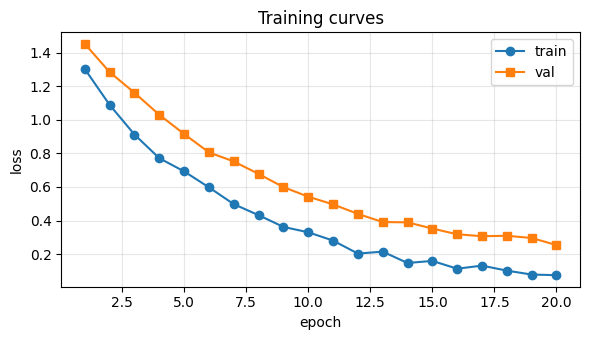

In [55]:
import matplotlib.pyplot as plt

epochs = np.arange(1, 21)
rng = np.random.default_rng(0)
train_loss = 1.5 * np.exp(-epochs / 6) + 0.05 * rng.random(20)
val_loss = 1.5 * np.exp(-epochs / 7) + 0.15 + 0.05 * rng.random(20)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(epochs, train_loss, marker="o", label="train")
ax.plot(epochs, val_loss, marker="s", label="val")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Training curves")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
# plt.savefig("recap_files/curves.png", dpi=300)   # high-res figure for papers
plt.show()

**Turning a notebook into a script.** For long runs on a server, move code into `train.py` and pass settings from the terminal with `argparse`:
```python
import argparse
parser = argparse.ArgumentParser()
parser.add_argument("--lr", type=float, default=1e-3)
parser.add_argument("--epochs", type=int, default=10)
args = parser.parse_args()
print(args.lr, args.epochs)        # run: python train.py --lr 3e-4 --epochs 50
```
Other notebook helpers: `%load_ext autoreload` + `%autoreload 2` (auto-reload your edited modules), `%time` (time one run), `?func` (quick docs).

### 🧠 Practice

1. Write a generator `sliding_windows(seq, size)` that yields every window of length `size` (useful for time series).
2. Plot an accuracy curve from your own list of numbers, with labels and a grid.
3. Use `with timed(...)` to compare a list comprehension and NumPy for squaring one million numbers.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
def sliding_windows(seq, size):
    for i in range(len(seq) - size + 1):
        yield seq[i:i + size]
print(list(sliding_windows([1, 2, 3, 4, 5], 3)))

acc = [0.5, 0.62, 0.7, 0.76, 0.8]
plt.plot(range(1, 6), acc, marker="o")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.grid(alpha=0.3); plt.show()

with timed("list comprehension"):
    sq = [i * i for i in range(1_000_000)]
with timed("numpy"):
    sq = np.arange(1_000_000) ** 2
```

</details>

## Chapter 26 · 🏁 Capstone: Logistic Regression from Scratch ⏱️ ~12 min

Time to use almost everything at once: **NumPy, classes, functions, loops, dicts, f-strings, files, and plots**.
We build a binary classifier with gradient descent, the same loop that trains neural networks.

**The math in plain words**
1. Score: $z = Xw + b$
2. Probability: $p = \sigma(z) = \frac{1}{1+e^{-z}}$
3. Loss (binary cross-entropy): $L = -\text{mean}\big(y\log p + (1-y)\log(1-p)\big)$
4. Gradients: $\nabla_w = \frac{1}{n}X^\top(p-y)$, $\;\nabla_b = \text{mean}(p-y)$
5. Update: $w \leftarrow w - \eta\nabla_w$, and the same for $b$

In [56]:
import numpy as np, json
from pathlib import Path

rng = np.random.default_rng(42)
n = 400
X0 = rng.normal(loc=[-1.5, -1.0], scale=1.0, size=(n // 2, 2))   # class 0 cloud
X1 = rng.normal(loc=[1.5, 1.0], scale=1.0, size=(n // 2, 2))     # class 1 cloud
X = np.vstack([X0, X1])
y = np.array([0] * (n // 2) + [1] * (n // 2))

perm = rng.permutation(n)                     # shuffle
X, y = X[perm], y[perm]
split = int(0.8 * n)
X_train, X_test, y_train, y_test = X[:split], X[split:], y[:split], y[split:]

mu, sd = X_train.mean(axis=0), X_train.std(axis=0)    # fit the scaler on TRAIN only
X_train, X_test = (X_train - mu) / sd, (X_test - mu) / sd
print(X_train.shape, X_test.shape, "positive rate:", y_train.mean().round(2))

(320, 2) (80, 2) positive rate: 0.5


In [57]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=200, verbose=True):
        self.lr, self.epochs, self.verbose = lr, epochs, verbose
        self.history = {"loss": [], "acc": []}

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        for epoch in range(1, self.epochs + 1):
            p = self._sigmoid(X @ self.w + self.b)                       # forward
            loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
            grad_w = X.T @ (p - y) / n                                    # backward
            grad_b = np.mean(p - y)
            self.w -= self.lr * grad_w                                    # update
            self.b -= self.lr * grad_b
            self.history["loss"].append(float(loss))                      # log
            self.history["acc"].append(float(((p >= 0.5) == y).mean()))
            if self.verbose and epoch % 50 == 0:
                print(f"epoch {epoch:3d} | loss {loss:.4f} | train acc {self.history['acc'][-1]:.3f}")
        return self                                                       # allows chaining

    def predict_proba(self, X):
        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model = LogisticRegression(lr=0.5, epochs=200).fit(X_train, y_train)
print("weights:", model.w.round(3), "bias:", round(float(model.b), 3))

epoch  50 | loss 0.1681 | train acc 0.950
epoch 100 | loss 0.1501 | train acc 0.950
epoch 150 | loss 0.1439 | train acc 0.953
epoch 200 | loss 0.1410 | train acc 0.953
weights: [3.484 1.847] bias: 0.282


In [58]:
def binary_metrics(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"acc": (tp + tn) / len(y_true), "precision": precision, "recall": recall,
            "f1": f1, "confusion": [[tn, fp], [fn, tp]]}

results = binary_metrics(y_test, model.predict(X_test))
for k, v in results.items():
    print(f"{k:>10}: {v if k == 'confusion' else round(v, 3)}")

Path("recap_files").mkdir(exist_ok=True)
out = Path("recap_files") / "logreg_results.json"
out.write_text(json.dumps({"weights": model.w.tolist(), "bias": float(model.b), **results}, indent=2))
print("saved to", out)

       acc: 0.975
 precision: 0.976
    recall: 0.976
        f1: 0.976
 confusion: [[38, 1], [1, 40]]
saved to recap_files\logreg_results.json


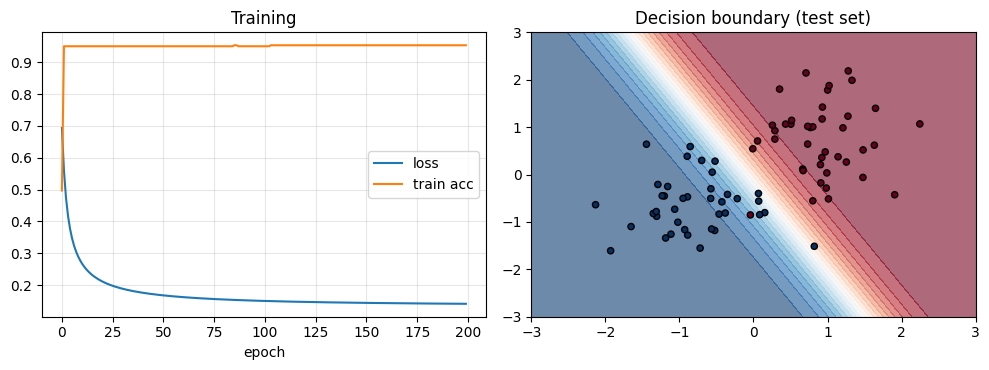

In [59]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(model.history["loss"], label="loss")
axes[0].plot(model.history["acc"], label="train acc")
axes[0].set_xlabel("epoch"); axes[0].set_title("Training"); axes[0].legend(); axes[0].grid(alpha=0.3)

xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, levels=20, cmap="RdBu_r", alpha=0.6)
axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="RdBu_r", edgecolor="k", s=20)
axes[1].set_title("Decision boundary (test set)")
plt.tight_layout()
plt.show()

### 🧠 Practice

1. Train with learning rates `[0.01, 0.1, 1.0]` (`verbose=False`) and store the final loss of each in a dict. Which converges best in 200 epochs?
2. Add **L2 regularisation**: in `fit`, change the weight gradient to `grad_w = X.T @ (p - y) / n + lam * self.w`. What happens to the weights when `lam` is large?
3. Try thresholds `0.3, 0.5, 0.7` on the test set and print precision and recall. Which threshold would you choose for a disease screening tool, and why?

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
final = {}
for lr in [0.01, 0.1, 1.0]:
    m = LogisticRegression(lr=lr, epochs=200, verbose=False).fit(X_train, y_train)
    final[lr] = round(m.history["loss"][-1], 4)
print(final)

# 2) Subclass and override fit with an extra `lam` term (or edit the class directly):
#    grad_w = X.T @ (p - y) / n + lam * self.w
#    Large lam pushes the weights toward 0 (simpler model, less overfitting).

for t in [0.3, 0.5, 0.7]:
    r = binary_metrics(y_test, model.predict(X_test, threshold=t))
    print(f"threshold {t}: precision={r['precision']:.3f} recall={r['recall']:.3f}")
# For screening, missing a sick patient is costly, so a lower threshold (higher recall) is usually preferred.
```

</details>

---
# Part F · NLP and Text Processing for ML Researchers

## Chapter 27 · Text Tokenization and Normalization ⏱️ ~8 min

Before language models can process raw text, sentences must be broken down into discrete numerical units called **tokens**. 

In modern ML research, tokenization lies at the boundary between raw data and tensor operations:
* **Character-level**: No unknown words, but sequences become excessively long.
* **Word-level**: Simple and intuitive, but struggles with out-of-vocabulary (OOV) terms.
* **Sub-word (BPE / WordPiece)**: The industry standard in modern LLMs (LLaMA, GPT, BERT).

Before using complex tokenizers, researchers must understand **text normalization** (casing, punctuation stripping, contractions) and how to write clean, deterministic tokenizers in pure Python.

In [60]:
import re

# Sample research log authored by male research leads
research_logs = (
    "Tariq and Khalid trained the 7B parameter transformer on 8 A100 GPUs. "
    "Rahim observed a gradient anomaly at step 4200! David applied gradient clipping (max_norm=1.0), "
    "and training loss dropped smoothly from 3.84 to 1.92. Isn't that impressive?"
)

def tokenize_research_text(text: str) -> list[str]:
    """Standardizes text to lowercase and extracts word tokens and contraction words."""
    text = text.lower()
    # Matches words, numbers, and contractions like isn't
    tokens = re.findall(r"\b[a-z0-9]+(?:'[a-z]+)?\b", text)
    return tokens

tokens = tokenize_research_text(research_logs)
print(f"Total tokens extracted: {len(tokens)}")
print("First 10 tokens:", tokens[:10])

# Frequency distribution using pure Python dictionary
token_freqs = {}
for tok in tokens:
    token_freqs[tok] = token_freqs.get(tok, 0) + 1

# Top 5 most frequent tokens
sorted_freqs = sorted(token_freqs.items(), key=lambda item: -item[1])[:5]
print("Top 5 frequent tokens:", sorted_freqs)

Total tokens extracted: 40
First 10 tokens: ['tariq', 'and', 'khalid', 'trained', 'the', '7b', 'parameter', 'transformer', 'on', '8']
Top 5 frequent tokens: [('and', 2), ('gradient', 2), ('1', 2), ('tariq', 1), ('khalid', 1)]


### 🧠 Practice

1. Write a function `extract_researcher_mentions(text, known_names)` that returns all names from `known_names = ["khalid", "tariq", "rahim", "david"]` mentioned in a log string.
2. Given a list of sentences, write a list comprehension that tokenizes each sentence and returns only tokens with length >= 4.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
known_names = {"khalid", "tariq", "rahim", "david"}
def extract_researcher_mentions(text, names_set):
    tokens = set(tokenize_research_text(text))
    return tokens.intersection(names_set)

print("Found researchers:", extract_researcher_mentions(research_logs, known_names))

sentences = ["Khalid benchmarks latency", "Tariq fine-tunes weights"]
long_tokens = [[tok for tok in tokenize_research_text(s) if len(tok) >= 4] for s in sentences]
print("Long tokens:", long_tokens)
```

</details>

## Chapter 28 · Vocabulary and Token-to-ID Indexing ⏱️ ~10 min

Neural networks cannot perform dot products on string characters. Every unique token in your dataset must map to a unique integer ID (`token_to_idx`), and back (`idx_to_token`).

PyTorch `nn.Embedding(num_embeddings, embedding_dim)` takes a tensor of these integer IDs as input.

### Special Tokens in ML Research
* `<pad>` (index 0): Pads variable-length sentences in a batch to identical length.
* `<unk>` (index 1): Replaces words unseen during training to prevent crashes.
* `<bos>` / `<eos>`: Marks the Beginning and End of Sequence for autoregressive generation.

In [61]:
class Vocabulary:
    """Production-ready vocabulary mapping class built in pure Python."""
    def __init__(self, pad_token="<pad>", unk_token="<unk>", min_freq=1):
        self.pad_token = pad_token
        self.unk_token = unk_token
        self.min_freq = min_freq
        
        self.token_to_idx = {self.pad_token: 0, self.unk_token: 1}
        self.idx_to_token = {0: self.pad_token, 1: self.unk_token}
        self.counts = {}

    def build_vocab(self, corpus: list[str]):
        """Extract unique words and assign index IDs ordered by frequency."""
        for doc in corpus:
            for tok in tokenize_research_text(doc):
                self.counts[tok] = self.counts.get(tok, 0) + 1
                
        for tok, count in sorted(self.counts.items(), key=lambda item: -item[1]):
            if count >= self.min_freq and tok not in self.token_to_idx:
                new_idx = len(self.token_to_idx)
                self.token_to_idx[tok] = new_idx
                self.idx_to_token[new_idx] = tok

    def encode(self, text: str) -> list[int]:
        """Convert text string to sequence of integer token IDs."""
        tokens = tokenize_research_text(text)
        unk_idx = self.token_to_idx[self.unk_token]
        return [self.token_to_idx.get(tok, unk_idx) for tok in tokens]

    def decode(self, indices: list[int]) -> str:
        """Convert list of token IDs back into readable string."""
        return " ".join([self.idx_to_token.get(idx, self.unk_token) for idx in indices])

    def __len__(self):
        return len(self.token_to_idx)

# Example corpus featuring male research collaborators
research_corpus = [
    "Khalid initialized the transformer weights with Xavier normal initialization.",
    "Tariq evaluated the multihead self-attention layers on validation data.",
    "Rahim optimized the AdamW learning rate with a cosine decay schedule.",
    "Karim monitored the cross-entropy loss across 50 epochs.",
    "Farhan logged validation perplexity and saved model checkpoints.",
    "David implemented rotary positional embeddings for long contexts.",
    "Alex analyzed gradient flow through the residual connections."
]

vocab = Vocabulary(min_freq=1)
vocab.build_vocab(research_corpus)

sample_query = "Khalid and Tariq optimized the loss"
encoded_ids = vocab.encode(sample_query)
decoded_text = vocab.decode(encoded_ids)

print(f"Vocabulary Size: {len(vocab)} unique tokens")
print(f"Query: '{sample_query}'")
print(f"Encoded IDs: {encoded_ids}")
print(f"Decoded: '{decoded_text}'")

Vocabulary Size: 59 unique tokens
Query: 'Khalid and Tariq optimized the loss'
Encoded IDs: [5, 40, 12, 21, 2, 33]
Decoded: 'khalid and tariq optimized the loss'


### 🧠 Practice

1. Encode the sentence `"Alex noticed an unknown token"`. Verify that the unknown word maps to the `<unk>` ID (`1`).
2. Write a function `pad_batch(batch_ids, pad_idx=0)` that pads a list of variable-length ID lists to equal length using NumPy.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
test_encoded = vocab.encode("Alex noticed an unknown token")
print("Encoded with UNK:", test_encoded)

import numpy as np
def pad_batch(batch_ids, pad_idx=0):
    max_len = max(len(seq) for seq in batch_ids)
    padded = np.full((len(batch_ids), max_len), fill_value=pad_idx, dtype=int)
    for i, seq in enumerate(batch_ids):
        padded[i, :len(seq)] = seq
    return padded

sample_batch = [[4, 12, 18], [2, 7], [9, 15, 21, 33]]
print("Padded batch array:\n", pad_batch(sample_batch))
```

</details>

## Chapter 29 · Vectorization: BoW and TF-IDF from Scratch ⏱️ ~12 min

Traditional and hybrid ML models require tabular numerical matrices where each row is a document and each column represents a vocabulary feature.

* **Bag of Words (BoW)**: Simply counts how many times word $t$ occurs in document $d$. Disadvantage: frequent non-informative words like `"the"`, `"is"` dominate the gradient.
* **TF-IDF (Term Frequency - Inverse Document Frequency)**: Discounts words that appear everywhere across the dataset:

$$TF(t, d) = 1 + \log(count(t, d)) \quad \text{if } count > 0$$
$$IDF(t, D) = \log\left(\frac{1 + N}{1 + DF(t)}\right) + 1$$

Each row vector is then **$L_2$ normalized** so that long documents don't artificially receive higher dot-product similarity than concise documents.

In [62]:
import numpy as np

class PureNumpyTFIDF:
    """Pure NumPy implementation of TF-IDF feature extraction with L2 normalization."""
    def __init__(self):
        self.vocab = {}
        self.idf_vector = None

    def fit_transform(self, documents: list[str]) -> np.ndarray:
        doc_tokens = [tokenize_research_text(doc) for doc in documents]
        unique_tokens = sorted(list({tok for toks in doc_tokens for tok in toks}))
        self.vocab = {tok: idx for idx, tok in enumerate(unique_tokens)}
        n_docs = len(documents)
        n_vocab = len(self.vocab)
        
        # 1. Raw Count Matrix
        tf_matrix = np.zeros((n_docs, n_vocab), dtype=np.float64)
        for doc_idx, toks in enumerate(doc_tokens):
            for tok in toks:
                if tok in self.vocab:
                    tf_matrix[doc_idx, self.vocab[tok]] += 1.0
                    
        # 2. Sublinear Term Frequency
        tf_scaled = np.zeros_like(tf_matrix)
        pos_mask = tf_matrix > 0
        tf_scaled[pos_mask] = 1.0 + np.log(tf_matrix[pos_mask])
        
        # 3. Document Frequency & Smoothed IDF
        df_vector = np.sum(tf_matrix > 0, axis=0)
        self.idf_vector = np.log((1.0 + n_docs) / (1.0 + df_vector)) + 1.0
        
        # 4. TF-IDF
        tfidf_matrix = tf_scaled * self.idf_vector
        
        # 5. L2 Normalization per document
        norms = np.linalg.norm(tfidf_matrix, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return tfidf_matrix / norms

    def transform(self, new_docs: list[str]) -> np.ndarray:
        n_docs = len(new_docs)
        n_vocab = len(self.vocab)
        tf_matrix = np.zeros((n_docs, n_vocab), dtype=np.float64)
        
        for doc_idx, doc in enumerate(new_docs):
            for tok in tokenize_research_text(doc):
                if tok in self.vocab:
                    tf_matrix[doc_idx, self.vocab[tok]] += 1.0
                    
        tf_scaled = np.zeros_like(tf_matrix)
        pos_mask = tf_matrix > 0
        tf_scaled[pos_mask] = 1.0 + np.log(tf_matrix[pos_mask])
        
        tfidf_matrix = tf_scaled * self.idf_vector
        norms = np.linalg.norm(tfidf_matrix, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return tfidf_matrix / norms

vectorizer = PureNumpyTFIDF()
X_tfidf = vectorizer.fit_transform(research_corpus)
print(f"TF-IDF Matrix Shape: {X_tfidf.shape} (documents x vocabulary)")

# Document Similarity via Cosine Similarity (Dot product of L2-normalized vectors)
sim_0_1 = float(np.dot(X_tfidf[0], X_tfidf[1]))
print(f"Cosine Similarity between Doc 0 (Khalid) and Doc 1 (Tariq): {sim_0_1:.4f}")

TF-IDF Matrix Shape: (7, 57) (documents x vocabulary)
Cosine Similarity between Doc 0 (Khalid) and Doc 1 (Tariq): 0.0344


### 🧠 Practice

1. Given the learned vocabulary, find the word index corresponding to `"transformer"`. What is its IDF score?
2. Write a function `find_most_similar_doc(query, vectorizer, doc_vectors)` that returns the index of the document most similar to `query`.

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
idx_transformer = vectorizer.vocab.get("transformer")
idf_val = vectorizer.idf_vector[idx_transformer]
print(f"'transformer' index: {idx_transformer}, IDF: {idf_val:.4f}")

def find_most_similar_doc(query, vec, doc_matrix):
    q_vec = vec.transform([query])[0]
    scores = np.dot(doc_matrix, q_vec)
    best_idx = int(np.argmax(scores))
    return best_idx, scores[best_idx]

best_i, best_sim = find_most_similar_doc("Tariq attention validation", vectorizer, X_tfidf)
print(f"Most similar document index: {best_i} with similarity {best_sim:.4f}")
print("Content:", research_corpus[best_i])
```

</details>

## Chapter 30 · 🏁 NLP Capstone: Peer-Review Classifier from Scratch ⏱️ ~14 min

Let's bring everything from Part D, Part E, and Part F together into a complete machine learning pipeline.

We will build an end-to-end **Peer-Review Sentiment Classifier** in pure Python and NumPy:
1. **Raw review comments** authored by male peer reviewers (Khalid, Tariq, Rahim, Karim, David, Farhan, Alex).
2. **Text tokenization and TF-IDF feature extraction** from scratch.
3. **Logistic Regression training** using the gradient descent algorithm implemented in Chapter 26.
4. **Model inference, accuracy, precision, and confusion matrix evaluation**.

In [63]:
# Peer review dataset labeled by male research reviewers
training_reviews = [
    # Positive peer reviews (1: Accept)
    ("Khalid: Exceptional research contribution with rigorous mathematical proofs.", 1),
    ("Tariq: Solid ablation study and impressive speedup on modern GPUs.", 1),
    ("Rahim: Outstanding empirical evaluation on ImageNet and benchmark datasets.", 1),
    ("Karim: Clear presentation, elegant formulation, and reproducible codebase.", 1),
    ("Farhan: Thorough error analysis and significant improvement over prior baselines.", 1),
    ("David: Novel attention mechanism that scales efficiently to long contexts.", 1),
    ("Alex: Excellent methodological rigor with insightful theoretical guarantees.", 1),
    ("Omar: Comprehensive experimental validation with consistent performance gains.", 1),
    ("Hasan: High quality writing and insightful discussion of ethical limitations.", 1),
    ("Zayn: Compelling results across all five NLP benchmarks with clean code.", 1),
    # Negative peer reviews (0: Reject)
    ("Khalid: Baseline comparisons are missing and empirical claims are unsupported.", 0),
    ("Tariq: Severely flawed experimental methodology and missing hyperparameter details.", 0),
    ("Rahim: Inconsistent notation throughout the paper and confusing proofs.", 0),
    ("Karim: Poor evaluation metrics and trivial performance gain over standard models.", 0),
    ("Farhan: Results cannot be reproduced and code repository contains critical bugs.", 0),
    ("David: Highly marginal contribution with superficial analysis of failures.", 0),
    ("Alex: Lacks novelty and simply combines existing heuristics without insight.", 0),
    ("Omar: Training curves exhibit severe instability and overfitting is ignored.", 0),
    ("Hasan: Unsubstantiated claims with zero statistical significance tests.", 0),
    ("Zayn: The proposed architecture fails to outperform basic linear regression.", 0),
]

review_texts = [r[0] for r in training_reviews]
review_labels = np.array([r[1] for r in training_reviews], dtype=np.float64)

# 1. Feature Extraction
review_vectorizer = PureNumpyTFIDF()
X_train = review_vectorizer.fit_transform(review_texts)
y_train = review_labels

# 2. Pure NumPy Logistic Regression
class NLPLogisticRegression:
    def __init__(self, learning_rate=1.0, epochs=250):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        
        for _ in range(self.epochs):
            predictions = self.sigmoid(np.dot(X, self.weights) + self.bias)
            
            # Binary Cross Entropy Loss
            eps = 1e-15
            preds_clipped = np.clip(predictions, eps, 1.0 - eps)
            loss = -np.mean(y * np.log(preds_clipped) + (1.0 - y) * np.log(1.0 - preds_clipped))
            self.loss_history.append(loss)
            
            # Gradients
            error = predictions - y
            dw = (1.0 / n_samples) * np.dot(X.T, error)
            db = (1.0 / n_samples) * np.sum(error)
            
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        return self.sigmoid(np.dot(X, self.weights) + self.bias)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

# Train model
clf = NLPLogisticRegression(learning_rate=1.2, epochs=200)
clf.fit(X_train, y_train)

# Evaluation
train_preds = clf.predict(X_train)
acc = np.mean(train_preds == y_train)
print(f"Final Training BCE Loss: {clf.loss_history[-1]:.4f}")
print(f"Training Accuracy: {acc * 100:.1f}%")

# Inference on unseen reviews
unseen_reviews = [
    "Tariq: Superb experimental evaluation with insightful proofs and clean reproducibility.",
    "Khalid: The experiments lack statistical rigor and baseline results are flawed."
]
X_unseen = review_vectorizer.transform(unseen_reviews)
unseen_probs = clf.predict_proba(X_unseen)

for rev, prob in zip(unseen_reviews, unseen_probs):
    decision = "ACCEPT" if prob >= 0.5 else "REJECT"
    print(f"\nReview: {rev}\nDecision: {decision} (confidence: {prob:.3f})")

Final Training BCE Loss: 0.1112
Training Accuracy: 100.0%

Review: Tariq: Superb experimental evaluation with insightful proofs and clean reproducibility.
Decision: ACCEPT (confidence: 0.771)

Review: Khalid: The experiments lack statistical rigor and baseline results are flawed.
Decision: REJECT (confidence: 0.160)


### 🧠 Practice

1. Identify the top 3 words with the highest positive weights (strongest indicators of paper acceptance).
2. Identify the top 3 words with the lowest negative weights (strongest indicators of rejection).

<details>
<summary>💡 <b>Show solution</b> (try first!)</summary>

```python
vocab_list = sorted(list(review_vectorizer.vocab.items()), key=lambda x: x[1])
idx_to_word = [w for w, i in vocab_list]

top_pos_indices = np.argsort(clf.weights)[-3:][::-1]
top_neg_indices = np.argsort(clf.weights)[:3]

print("Top 3 Acceptance Words:", [idx_to_word[i] for i in top_pos_indices])
print("Top 3 Rejection Words:", [idx_to_word[i] for i in top_neg_indices])
```

</details>

---
# 📋 One-Page Cheat Sheet

| Topic | Remember this |
|---|---|
| Types | `int float str bool None list tuple set dict`, check with `type()` |
| Strings | `f"{x:.4f}"`, `.split() .join() .strip() .replace()` |
| Lists | `.append .extend .pop .sort`, `sorted()`, copy with `.copy()` |
| Tuples | fixed, unpack `h, w, c = shape` |
| Sets | unique items, `& \| - ^`, leakage checks |
| Dicts | `.get(k, default)`, `.items()`, merge `a \| b`, `Counter`, `defaultdict` |
| Control | `if/elif/else`, `for` + `enumerate`/`zip`, `while`, `break/continue` |
| Functions | defaults, `*args`, `**kwargs`, no mutable defaults, return values |
| Comprehensions | `[f(x) for x in xs if cond]`, `{k: v for ...}` |
| Functional | `lambda`, `sorted(key=)`, closures, `@decorator` |
| Errors | read tracebacks bottom-up; `try/except/else/finally`; `raise`; `assert` |
| Files | `with open()`, `pathlib.Path`, `json`, `csv`, `pickle` (trusted only) |
| Envs | one venv/conda env per project, `pip freeze > requirements.txt` |
| OOP | `__init__`, `self`, `__len__`/`__getitem__`/`__call__`, `super()`, `@dataclass` |
| NumPy | `shape`, `reshape(-1)`, masks, broadcasting, `axis`, `@`, `default_rng(seed)` |
| Pandas | `read_csv`, `loc/iloc`, filter with `&`, `fillna`, `groupby().agg()`, `to_numpy()` |
| Research | seed everything, fit scalers on train only, log with `logging`, plot curves |

## 🚀 Where to go next
1. **PyTorch basics**: tensors (just NumPy on GPU), `Dataset`/`DataLoader`, `nn.Module`, the training loop you already wrote.
2. **scikit-learn**: pipelines, cross-validation, metrics.
3. **Experiment tracking**: Weights & Biases or MLflow.
4. **Clean research code**: type hints, small functions, tests with `pytest`, Git.

*Credit: chapter structure inspired by Asabeneh Yetayeh's open-source [30 Days of Python](https://github.com/Asabeneh/30-Days-Of-Python).*
| NLP | `tokenize_research_text()`, `Vocabulary(min_freq=1)`, TF-IDF L2 norm |

In [64]:
# Optional clean-up: delete the files this notebook created
# import shutil, os
# shutil.rmtree("recap_files", ignore_errors=True)
# if os.path.exists("mlutils.py"): os.remove("mlutils.py")